# 02 — Climate and Electricity Feature Engineering

This notebook consolidates the project's climate and electricity feature-engineering work.

It preserves the original ERA5/NetCDF processing, HDD and CDD calculations, climate-region assignment, and construction of weather- and household-normalized electricity measures used later in the municipal adoption models.


## Source provenance

This polished notebook consolidates the following original work:

- `weatherData.ipynb` — Initial ERA5/NetCDF temperature processing and heating-degree-day calculations for Massachusetts climate regions and analysis years.
- `eda_with_hdd(1).ipynb` — Expanded HDD workflow, municipal climate-region mapping, merges with electricity/adoption data, and HDD-normalized analysis.
- `cooling_degree_days.ipynb` — Cooling-degree-day processing and CDD-normalized summer electricity feature construction.
- `filtered_dataset_eda(1).ipynb` — Construction and testing of household- and HDD-normalized winter electricity, including `elec_per_hh_per_hdd_2023` and related comparisons.

No analytical code from the source files was silently replaced. The purpose of this version is to make the workflow easier to follow in a public research repository.


---
## Original analysis section: `weatherData.ipynb`

**What this section contains:** Initial ERA5/NetCDF temperature processing and heating-degree-day calculations for Massachusetts climate regions and analysis years.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [1]:
from google.colab import files
uploaded = files.upload()

Saving boston_jan_2024.nc to boston_jan_2024.nc


In [2]:
from google.colab import files
uploaded = files.upload()

Saving boston_feb_2024.nc to boston_feb_2024.nc


In [3]:
from google.colab import files
uploaded = files.upload()

Saving boston_mar_2024.nc to boston_mar_2024.nc


In [4]:
import xarray as xr
import pandas as pd

In [7]:
import xarray as xr

files_list = [
    "boston_jan_2024.nc",
    "boston_feb_2024.nc",
    "boston_mar_2024.nc"
]

ds = xr.open_mfdataset(files_list, combine="by_coords")
ds

<xarray.Dataset> Size: 192kB
Dimensions:     (valid_time: 2184, latitude: 4, longitude: 4)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 17kB 2024-01-01 ... 2024-03-31T23...
  * latitude    (latitude) float64 32B 42.5 42.4 42.3 42.2
  * longitude   (longitude) float64 32B -71.2 -71.1 -71.0 -70.9
    number      int64 8B 0
    expver      (valid_time) <U4 35kB dask.array<chunksize=(744,), meta=np.ndarray>
Data variables:
    t2m         (valid_time, latitude, longitude) float32 140kB dask.array<chunksize=(744, 4, 4), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-04-06T18:06 GRIB to CDM+CF via cfgrib-0.9.1...

In [8]:
temp_F = (ds["t2m"] - 273.15) * 9/5 + 32

In [9]:
df = temp_F.to_dataframe().reset_index()
df.head()

,valid_time,latitude,longitude,number,expver,t2m
0,2024-01-01,42.5,-71.2,0,0001,32.555634
1,2024-01-01,42.5,-71.1,0,0001,33.329071
2,2024-01-01,42.5,-71.0,0,0001,34.348602
3,2024-01-01,42.5,-70.9,0,0001,35.034149
4,2024-01-01,42.4,-71.2,0,0001,32.358757


In [11]:
print(df.columns)

Index(['valid_time', 'latitude', 'longitude', 'number', 'expver', 't2m'], dtype='object')


In [12]:
hourly_avg = df.groupby("valid_time")["t2m"].mean().reset_index()

In [13]:
import pandas as pd

hourly_avg["valid_time"] = pd.to_datetime(hourly_avg["valid_time"])
hourly_avg["date"] = hourly_avg["valid_time"].dt.date

In [14]:
daily_temp = hourly_avg.groupby("date")["t2m"].mean().reset_index()

In [15]:
daily_temp["HDD"] = (65 - daily_temp["t2m"]).clip(lower=0)

In [16]:
winter_hdd = daily_temp["HDD"].sum()

print("Boston Winter HDD (Jan–Mar 2024):", winter_hdd)

Boston Winter HDD (Jan–Mar 2024): 2732.6104


In [3]:
from google.colab import files
uploaded = files.upload()

Saving weather_2024.zip to weather_2024.zip


In [4]:
import zipfile

with zipfile.ZipFile("weather_2024.zip", "r") as zip_ref:
    zip_ref.extractall()

print("Extracted successfully")

Extracted successfully


In [5]:
import os
print(os.listdir("/content"))

['.config', 'pittsfield_jan_2024.nc', 'pittsfield_mar_2024.nc', 'springfield_jan_2024.nc', 'springfield_feb_2024.nc', 'worcester_mar-2024.nc', 'worcester_feb_2024.nc', 'weather_2024.zip', 'worcester_jan_2024.nc', 'springfield_mar_2024.nc', 'pittsfield_feb_2024.nc', 'sample_data']


In [6]:
import xarray as xr
import pandas as pd

In [7]:
def compute_winter_hdd(files_list, region_name):
    ds = xr.open_mfdataset(files_list, combine="by_coords")

    temp_F = (ds["t2m"] - 273.15) * 9/5 + 32
    df = temp_F.to_dataframe().reset_index()

    hourly_avg = df.groupby("valid_time")["t2m"].mean().reset_index()
    hourly_avg["valid_time"] = pd.to_datetime(hourly_avg["valid_time"])
    hourly_avg["date"] = hourly_avg["valid_time"].dt.date

    daily_temp = hourly_avg.groupby("date")["t2m"].mean().reset_index()
    daily_temp["HDD"] = (65 - daily_temp["t2m"]).clip(lower=0)

    winter_hdd = daily_temp["HDD"].sum()

    print(f"{region_name} Winter HDD (Jan–Mar 2024): {winter_hdd}")
    return winter_hdd, daily_temp

In [9]:
worcester_files = [
    "worcester_jan_2024.nc",
    "worcester_feb_2024.nc",
    "worcester_mar-2024.nc"
]

worcester_hdd, worcester_daily = compute_winter_hdd(worcester_files, "Worcester")

Worcester Winter HDD (Jan–Mar 2024): 2877.03271484375


In [10]:
springfield_files = [
    "springfield_jan_2024.nc",
    "springfield_feb_2024.nc",
    "springfield_mar_2024.nc"
]

springfield_hdd, springfield_daily = compute_winter_hdd(springfield_files, "Springfield")

Springfield Winter HDD (Jan–Mar 2024): 2806.962646484375


In [11]:
pittsfield_files = [
    "pittsfield_jan_2024.nc",
    "pittsfield_feb_2024.nc",
    "pittsfield_mar_2024.nc"
]

pittsfield_hdd, pittsfield_daily = compute_winter_hdd(pittsfield_files, "Pittsfield")

Pittsfield Winter HDD (Jan–Mar 2024): 3117.519775390625


In [12]:
results_2024 = pd.DataFrame({
    "Region": ["Boston", "Worcester", "Springfield", "Pittsfield"],
    "Winter_HDD_2024": [2732.6104, worcester_hdd, springfield_hdd, pittsfield_hdd]
})

results_2024

,Region,Winter_HDD_2024
0,Boston,2732.610400
1,Worcester,2877.032715
2,Springfield,2806.962646
3,Pittsfield,3117.519775


In [13]:
results_2024.to_csv("winter_hdd_2024_regions.csv", index=False)
print("Saved winter_hdd_2024_regions.csv")

Saved winter_hdd_2024_regions.csv


In [14]:
from google.colab import files
uploaded = files.upload()

Saving weather_2013.zip to weather_2013.zip


In [15]:
import zipfile

with zipfile.ZipFile("weather_2013.zip", "r") as zip_ref:
    zip_ref.extractall()

print("Extracted successfully")

Extracted successfully


In [18]:
import os

for root, dirs, files_in in os.walk("/content"):
    for f in sorted(files_in):
        if f.endswith(".nc"):
            print(os.path.join(root, f))

/content/boston_2013_feb.nc
/content/boston_2013_jan.nc
/content/boston_2013_mar.nc
/content/pittsfield_2013_feb.nc
/content/pittsfield_2013_jan.nc
/content/pittsfield_2013_mar.nc
/content/pittsfield_feb_2024.nc
/content/pittsfield_jan_2024.nc
/content/pittsfield_mar_2024.nc
/content/springfield_2013_feb.nc
/content/springfield_2013_jan.nc
/content/springfield_2013_mar.nc
/content/springfield_feb_2024.nc
/content/springfield_jan_2024.nc
/content/springfield_mar_2024.nc
/content/worcester_2013_feb.nc
/content/worcester_2013_jan.nc
/content/worcester_2013_mar.nc
/content/worcester_feb_2024.nc
/content/worcester_jan_2024.nc
/content/worcester_mar-2024.nc


In [19]:
def compute_winter_hdd(files_list, region_name):
    ds = xr.open_mfdataset(files_list, combine="by_coords")

    # Kelvin -> Fahrenheit
    temp_F = (ds["t2m"] - 273.15) * 9/5 + 32

    # to dataframe
    df = temp_F.to_dataframe().reset_index()

    # average across the small regional box each hour
    hourly_avg = df.groupby("valid_time")["t2m"].mean().reset_index()

    # hourly -> daily
    hourly_avg["valid_time"] = pd.to_datetime(hourly_avg["valid_time"])
    hourly_avg["date"] = hourly_avg["valid_time"].dt.date
    daily_temp = hourly_avg.groupby("date")["t2m"].mean().reset_index()

    # HDD base 65F
    daily_temp["HDD"] = (65 - daily_temp["t2m"]).clip(lower=0)

    winter_hdd = daily_temp["HDD"].sum()

    print(f"{region_name} Winter HDD (Jan–Mar 2013): {winter_hdd}")
    return winter_hdd, daily_temp

In [22]:
boston_files_2013 = [
    "/content/boston_2013_jan.nc",
    "/content/boston_2013_feb.nc",
    "/content/boston_2013_mar.nc"
]

worcester_files_2013 = [
    "/content/worcester_2013_jan.nc",
    "/content/worcester_2013_feb.nc",
    "/content/worcester_2013_mar.nc"
]

springfield_files_2013 = [
    "/content/springfield_2013_jan.nc",
    "/content/springfield_2013_feb.nc",
    "/content/springfield_2013_mar.nc"
]

pittsfield_files_2013 = [
    "/content/pittsfield_2013_jan.nc",
    "/content/pittsfield_2013_feb.nc",
    "/content/pittsfield_2013_mar.nc"
]

In [23]:
boston_hdd_2013, boston_daily_2013 = compute_winter_hdd(boston_files_2013, "Boston")
worcester_hdd_2013, worcester_daily_2013 = compute_winter_hdd(worcester_files_2013, "Worcester")
springfield_hdd_2013, springfield_daily_2013 = compute_winter_hdd(springfield_files_2013, "Springfield")
pittsfield_hdd_2013, pittsfield_daily_2013 = compute_winter_hdd(pittsfield_files_2013, "Pittsfield")

Boston Winter HDD (Jan–Mar 2013): 3048.1640625
Worcester Winter HDD (Jan–Mar 2013): 3261.204833984375
Springfield Winter HDD (Jan–Mar 2013): 3199.530517578125
Pittsfield Winter HDD (Jan–Mar 2013): 3603.442626953125


In [24]:
results_compare = pd.DataFrame({
    "Region": ["Boston", "Worcester", "Springfield", "Pittsfield"],
    "Winter_HDD_2013": [
        boston_hdd_2013,
        worcester_hdd_2013,
        springfield_hdd_2013,
        pittsfield_hdd_2013
    ],
    "Winter_HDD_2024": [
        2732.610400,
        2877.032715,
        2806.962646,
        3117.519775
    ]
})

results_compare["HDD_change_2024_minus_2013"] = (
    results_compare["Winter_HDD_2024"] - results_compare["Winter_HDD_2013"]
)

results_compare

,Region,Winter_HDD_2013,Winter_HDD_2024,HDD_change_2024_minus_2013
0,Boston,3048.164062,2732.610400,-315.553662
1,Worcester,3261.204834,2877.032715,-384.172119
2,Springfield,3199.530518,2806.962646,-392.567872
3,Pittsfield,3603.442627,3117.519775,-485.922852


In [25]:
from google.colab import files
uploaded = files.upload()

Saving weather_2023.zip to weather_2023.zip


In [26]:
import zipfile

with zipfile.ZipFile("weather_2023.zip", "r") as zip_ref:
    zip_ref.extractall()

print("2023 files extracted")

2023 files extracted


In [27]:
boston_files_2023 = [
    "/content/boston_2023_jan.nc",
    "/content/boston_2023_feb.nc",
    "/content/boston_2023_mar.nc"
]

worcester_files_2023 = [
    "/content/worcester_2023_jan.nc",
    "/content/worcester_2023_feb.nc",
    "/content/worcester_2023_mar.nc"
]

springfield_files_2023 = [
    "/content/springfield_2023_jan.nc",
    "/content/springfield_2023_feb.nc",
    "/content/springfield_2023_mar.nc"
]

pittsfield_files_2023 = [
    "/content/pittsfield_2023_jan.nc",
    "/content/pittsfield_2023_feb.nc",
    "/content/pittsfield_2023_mar.nc"
]

In [28]:
boston_hdd_2023, _ = compute_winter_hdd(boston_files_2023, "Boston 2023")
worcester_hdd_2023, _ = compute_winter_hdd(worcester_files_2023, "Worcester 2023")
springfield_hdd_2023, _ = compute_winter_hdd(springfield_files_2023, "Springfield 2023")
pittsfield_hdd_2023, _ = compute_winter_hdd(pittsfield_files_2023, "Pittsfield 2023")

Boston 2023 Winter HDD (Jan–Mar 2013): 2587.40283203125
Worcester 2023 Winter HDD (Jan–Mar 2013): 2752.4755859375
Springfield 2023 Winter HDD (Jan–Mar 2013): 2676.711181640625
Pittsfield 2023 Winter HDD (Jan–Mar 2013): 3065.75439453125


In [29]:
results_final = pd.DataFrame({
    "Region": ["Boston", "Worcester", "Springfield", "Pittsfield"],
    "HDD_2013": [
        boston_hdd_2013,
        worcester_hdd_2013,
        springfield_hdd_2013,
        pittsfield_hdd_2013
    ],
    "HDD_2023": [
        boston_hdd_2023,
        worcester_hdd_2023,
        springfield_hdd_2023,
        pittsfield_hdd_2023
    ],
    "HDD_2024": [
        2732.610400,
        2877.032715,
        2806.962646,
        3117.519775
    ]
})

results_final

,Region,HDD_2013,HDD_2023,HDD_2024
0,Boston,3048.164062,2587.402832,2732.610400
1,Worcester,3261.204834,2752.475586,2877.032715
2,Springfield,3199.530518,2676.711182,2806.962646
3,Pittsfield,3603.442627,3065.754395,3117.519775


---
## Original analysis section: `eda_with_hdd(1).ipynb`

**What this section contains:** Expanded HDD workflow, municipal climate-region mapping, merges with electricity/adoption data, and HDD-normalized analysis.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [1]:
import os
import xarray as xr
import pandas as pd
import numpy as np

In [2]:
def compute_hdd_from_nc(file_path):
    ds = xr.open_dataset(file_path)

    # detect temperature variable
    possible_temp_vars = ["t2m", "temperature_c", "2m_temperature"]
    temp_var = None
    for v in possible_temp_vars:
        if v in ds.data_vars:
            temp_var = v
            break

    if temp_var is None:
        raise ValueError(f"Could not find temperature variable in {file_path}. Found: {list(ds.data_vars)}")

    df = ds[temp_var].to_dataframe().reset_index()

    # detect time column
    possible_time_cols = ["time", "valid_time"]
    time_col = None
    for c in possible_time_cols:
        if c in df.columns:
            time_col = c
            break

    if time_col is None:
        raise ValueError(f"Could not find time column in {file_path}. Found: {df.columns.tolist()}")

    df[time_col] = pd.to_datetime(df[time_col])

    # convert temperature to Fahrenheit
    # if variable is t2m or 2m_temperature, ERA5 usually stores in Kelvin
    if temp_var in ["t2m", "2m_temperature"]:
        df["temp_f"] = (df[temp_var] - 273.15) * 9/5 + 32
    else:
        # if already in Celsius
        df["temp_f"] = df[temp_var] * 9/5 + 32

    # daily average temperature
    df["date"] = df[time_col].dt.date
    daily = df.groupby("date", as_index=False)["temp_f"].mean()

    # HDD base 65 F
    daily["hdd"] = (65 - daily["temp_f"]).clip(lower=0)

    return daily["hdd"].sum()

In [3]:
from google.colab import files
uploaded = files.upload()

Saving weather_2013.zip to weather_2013.zip


In [4]:
from google.colab import files
uploaded = files.upload()

Saving weather_2023.zip to weather_2023.zip


In [5]:
from google.colab import files
uploaded = files.upload()

Saving weather_2024.zip to weather_2024.zip


In [6]:
import zipfile
import os

zip_files = ["weather_2013.zip", "weather_2023.zip", "weather_2024.zip"]

for z in zip_files:
    with zipfile.ZipFile(z, 'r') as zip_ref:
        zip_ref.extractall(z.replace(".zip", ""))

print("Unzipped successfully")

Unzipped successfully


In [7]:
os.listdir("weather_2013")

['boston_2013_jan.nc',
 'springfield_2013_feb.nc',
 'worcester_2013_mar.nc',
 'pittsfield_2013_feb.nc',
 'springfield_2013_mar.nc',
 'boston_2013_mar.nc',
 'worcester_2013_feb.nc',
 'worcester_2013_jan.nc',
 'boston_2013_feb.nc',
 'springfield_2013_jan.nc',
 'pittsfield_2013_jan.nc',
 'pittsfield_2013_mar.nc']

In [9]:
import xarray as xr
import pandas as pd
import numpy as np

def compute_hdd_from_nc(file_path):
    ds = xr.open_dataset(file_path)

    # detect temperature variable
    possible_temp_vars = ["t2m", "temperature_c", "2m_temperature"]
    temp_var = None
    for v in possible_temp_vars:
        if v in ds.data_vars:
            temp_var = v
            break

    if temp_var is None:
        raise ValueError(f"No temp variable found. Available: {list(ds.data_vars)}")

    df = ds[temp_var].to_dataframe().reset_index()

    # detect time column
    possible_time_cols = ["time", "valid_time"]
    time_col = None
    for c in possible_time_cols:
        if c in df.columns:
            time_col = c
            break

    if time_col is None:
        raise ValueError(f"No time column found. Available: {df.columns.tolist()}")

    df[time_col] = pd.to_datetime(df[time_col])

    # convert temp
    if temp_var in ["t2m", "2m_temperature"]:  # Kelvin
        df["temp_f"] = (df[temp_var] - 273.15) * 9/5 + 32
    else:  # Celsius
        df["temp_f"] = df[temp_var] * 9/5 + 32

    # daily average
    df["date"] = df[time_col].dt.date
    daily = df.groupby("date")["temp_f"].mean().reset_index()

    # HDD
    daily["hdd"] = (65 - daily["temp_f"]).clip(lower=0)

    return daily["hdd"].sum()

In [10]:
import os

def compute_winter_hdd_for_folder(folder_path, year):
    results = []

    for fname in os.listdir(folder_path):
        if fname.endswith(".nc"):
            file_path = os.path.join(folder_path, fname)

            region = fname.split("_")[0].lower()

            hdd = compute_hdd_from_nc(file_path)

            results.append({
                "region": region,
                "year": year,
                "file": fname,
                "monthly_hdd": hdd
            })

    df = pd.DataFrame(results)

    winter_hdd = df.groupby(["region", "year"], as_index=False)["monthly_hdd"].sum()
    winter_hdd = winter_hdd.rename(columns={"monthly_hdd": "winter_hdd"})

    return df, winter_hdd

In [11]:
monthly_2013, winter_2013 = compute_winter_hdd_for_folder("weather_2013", 2013)
monthly_2023, winter_2023 = compute_winter_hdd_for_folder("weather_2023", 2023)
monthly_2024, winter_2024 = compute_winter_hdd_for_folder("weather_2024", 2024)

winter_hdd_all = pd.concat([winter_2013, winter_2023, winter_2024], ignore_index=True)

winter_hdd_all

,region,year,winter_hdd
0,boston,2013,3048.163818
1,pittsfield,2013,3603.442383
2,springfield,2013,3199.531006
3,worcester,2013,3261.205078
4,boston,2023,2587.402832
5,pittsfield,2023,3065.754395
6,springfield,2023,2676.711182
7,worcester,2023,2752.475586
8,boston,2024,2732.610596
9,pittsfield,2024,3117.519531


In [13]:
!pip install us

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 360.5/360.5 kB 7.4 MB/s eta 0:00:00


In [14]:
import pandas as pd

# Load Massachusetts place data (Census)
url = "https://raw.githubusercontent.com/kjhealy/fips-codes/master/state_and_county_fips_master.csv"
fips_df = pd.read_csv(url)

fips_df.head()

,fips,name,state
0,0,UNITED STATES,NaN
1,1000,ALABAMA,NaN
2,1001,Autauga County,AL
3,1003,Baldwin County,AL
4,1005,Barbour County,AL


In [16]:
from google.colab import files
uploaded = files.upload()

Saving final_dataset_with_wsr.csv to final_dataset_with_wsr.csv


In [18]:
final_df = pd.read_csv("final_dataset_with_wsr.csv")

In [19]:
final_df.head()

,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,delivered_share_2013,delivered_share_change_13_23,gas_share_change_13_23,electric_share_change_13_23,delivered_share_change_13_24,gas_share_change_13_24,electric_share_change_13_24,wsr_2013,wsr_2023,wsr_2024
0,abington,6438,1053,2774,2484,0.163560,0.430879,0.385834,32.463498,6388,...,0.455329,-0.069495,0.030741,0.038345,-0.087452,0.057439,0.029449,0.917820,0.780765,0.779510
1,acton,9085,1483,4787,2719,0.163236,0.526912,0.299285,85.855806,9409,...,0.327397,-0.028113,0.011168,0.022182,-0.046602,0.004608,0.051952,1.090564,0.916251,0.934947
2,acushnet,4103,148,1758,2020,0.036071,0.428467,0.492323,51.913234,4173,...,0.507937,-0.015614,0.025657,0.016295,-0.028905,0.050581,0.016648,0.714673,0.723335,0.762751
3,adams,4081,333,2156,1507,0.081598,0.528302,0.369272,25.728988,4046,...,0.426721,-0.057448,0.061905,0.038413,-0.068095,0.075126,0.038130,1.018096,1.010372,0.954068
4,agawam,11792,2154,6512,2942,0.182666,0.552239,0.249491,28.154681,11979,...,0.206576,0.042916,-0.021650,-0.003817,0.005045,-0.008399,0.016372,0.835907,0.877038,0.789319


In [20]:
final_df.columns

Index(['municipality', 'total_households_2023', 'electric_fuel_2023',
       'gas_fuel_2023', 'delivered_fuels_2023', 'electric_share_2023',
       'gas_share_2023', 'delivered_share_2023', 'installs_per_1000_2023',
       'total_households_2024', 'electric_fuel_2024', 'gas_fuel_2024',
       'delivered_fuels_2024', 'electric_share_2024', 'gas_share_2024',
       'delivered_share_2024', 'installs_per_1000_2024',
       'electric_share_change_23_24', 'gas_share_change_23_24',
       'delivered_share_change_23_24', 'adoption_change_23_24',
       'total_households_2013', 'electric_fuel_2013', 'gas_fuel_2013',
       'delivered_fuels_2013', 'electric_share_2013', 'gas_share_2013',
       'delivered_share_2013', 'delivered_share_change_13_23',
       'gas_share_change_13_23', 'electric_share_change_13_23',
       'delivered_share_change_13_24', 'gas_share_change_13_24',
       'electric_share_change_13_24', 'wsr_2013', 'wsr_2023', 'wsr_2024'],
      dtype='object')

In [21]:
towns = sorted(
    final_df["municipality"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
    .unique()
)

towns[:50]

['abington',
 'acton',
 'acushnet',
 'adams',
 'agawam',
 'alford',
 'amesbury',
 'amherst',
 'andover',
 'aquinnah',
 'arlington',
 'ashburnham',
 'ashby',
 'ashfield',
 'ashland',
 'athol',
 'attleboro',
 'auburn',
 'avon',
 'ayer',
 'barnstable',
 'barre',
 'becket',
 'bedford',
 'belchertown',
 'bellingham',
 'belmont',
 'berkley',
 'berlin',
 'bernardston',
 'beverly',
 'billerica',
 'blackstone',
 'blandford',
 'bolton',
 'boston',
 'bourne',
 'boxborough',
 'boxford',
 'boylston',
 'braintree',
 'brewster',
 'bridgewater',
 'brimfield',
 'brockton',
 'brookfield',
 'brookline',
 'buckland',
 'burlington',
 'cambridge']

In [22]:
towns = sorted(final_df["municipality"].dropna().astype(str).str.strip().str.lower().unique())
towns[:50]

['abington',
 'acton',
 'acushnet',
 'adams',
 'agawam',
 'alford',
 'amesbury',
 'amherst',
 'andover',
 'aquinnah',
 'arlington',
 'ashburnham',
 'ashby',
 'ashfield',
 'ashland',
 'athol',
 'attleboro',
 'auburn',
 'avon',
 'ayer',
 'barnstable',
 'barre',
 'becket',
 'bedford',
 'belchertown',
 'bellingham',
 'belmont',
 'berkley',
 'berlin',
 'bernardston',
 'beverly',
 'billerica',
 'blackstone',
 'blandford',
 'bolton',
 'boston',
 'bourne',
 'boxborough',
 'boxford',
 'boylston',
 'braintree',
 'brewster',
 'bridgewater',
 'brimfield',
 'brockton',
 'brookfield',
 'brookline',
 'buckland',
 'burlington',
 'cambridge']

In [23]:
!pip install geopy

In [24]:
import pandas as pd
import time
from geopy.geocoders import Nominatim
from geopy.distance import geodesic

In [25]:
towns = sorted(
    final_df["municipality"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
    .unique()
)

len(towns), towns[:20]

(351,
 ['abington',
  'acton',
  'acushnet',
  'adams',
  'agawam',
  'alford',
  'amesbury',
  'amherst',
  'andover',
  'aquinnah',
  'arlington',
  'ashburnham',
  'ashby',
  'ashfield',
  'ashland',
  'athol',
  'attleboro',
  'auburn',
  'avon',
  'ayer'])

In [27]:
stations = {
    "boston": (
        (42.5 + 42.2) / 2,
        (-71.2 + -70.9) / 2
    ),
    "worcester": (
        (42.4 + 42.1) / 2,
        (-72.0 + -71.6) / 2
    ),
    "springfield": (
        (42.2 + 41.9) / 2,
        (-72.8 + -72.4) / 2
    ),
    "pittsfield": (
        (42.6 + 42.3) / 2,
        (-73.4 + -73.1) / 2
    )
}

stations

{'boston': (42.35, -71.05000000000001),
 'worcester': (42.25, -71.8),
 'springfield': (42.05, -72.6),
 'pittsfield': (42.45, -73.25)}

In [28]:
geolocator = Nominatim(user_agent="ma_heat_pump_analysis")

rows = []

for town in towns:
    query = f"{town}, Massachusetts, USA"
    try:
        location = geolocator.geocode(query, timeout=10)

        if location is not None:
            rows.append({
                "municipality": town,
                "latitude": location.latitude,
                "longitude": location.longitude
            })
        else:
            rows.append({
                "municipality": town,
                "latitude": None,
                "longitude": None
            })

        time.sleep(1)

    except Exception:
        rows.append({
            "municipality": town,
            "latitude": None,
            "longitude": None
        })
        time.sleep(1)

town_coords = pd.DataFrame(rows)
town_coords.head()

,municipality,latitude,longitude
0,abington,42.104823,-70.945322
1,acton,42.485093,-71.432840
2,acushnet,41.680659,-70.907816
3,adams,42.620943,-73.120413
4,agawam,42.068862,-72.615160


In [29]:
from geopy.distance import geodesic
import pandas as pd

# region centers (from your coordinates)
stations = {
    "boston": ( (42.5+42.2)/2 , (-71.2+-70.9)/2 ),
    "worcester": ( (42.4+42.1)/2 , (-72.0+-71.6)/2 ),
    "springfield": ( (42.2+41.9)/2 , (-72.8+-72.4)/2 ),
    "pittsfield": ( (42.6+42.3)/2 , (-73.4+-73.1)/2 )
}

def nearest_region(lat, lon):
    if pd.isna(lat) or pd.isna(lon):
        return None

    town_point = (lat, lon)

    best_region = None
    best_dist = float("inf")

    for region, coord in stations.items():
        dist = geodesic(town_point, coord).miles
        if dist < best_dist:
            best_dist = dist
            best_region = region

    return best_region

# apply
town_coords["region"] = town_coords.apply(
    lambda row: nearest_region(row["latitude"], row["longitude"]),
    axis=1
)

town_coords.head(10)

,municipality,latitude,longitude,region
0,abington,42.104823,-70.945322,boston
1,acton,42.485093,-71.432840,boston
2,acushnet,41.680659,-70.907816,boston
3,adams,42.620943,-73.120413,pittsfield
4,agawam,42.068862,-72.615160,springfield
5,alford,42.235937,-73.413462,pittsfield
6,amesbury,42.857954,-70.930092,boston
7,amherst,42.373195,-72.519876,springfield
8,andover,42.657170,-71.140878,boston
9,aquinnah,41.343136,-70.813675,boston


In [30]:
final_df["municipality"] = final_df["municipality"].str.strip().str.lower()
town_coords["municipality"] = town_coords["municipality"].str.strip().str.lower()
town_coords["region"] = town_coords["region"].str.strip().str.lower()

In [31]:
final_df = final_df.merge(
    town_coords[["municipality", "region"]],
    on="municipality",
    how="left"
)

In [32]:
final_df["region"].isna().sum()

np.int64(0)

In [33]:
hdd_2013 = winter_hdd_all[winter_hdd_all["year"] == 2013][["region", "winter_hdd"]].rename(columns={"winter_hdd": "winter_hdd_2013"})
hdd_2023 = winter_hdd_all[winter_hdd_all["year"] == 2023][["region", "winter_hdd"]].rename(columns={"winter_hdd": "winter_hdd_2023"})
hdd_2024 = winter_hdd_all[winter_hdd_all["year"] == 2024][["region", "winter_hdd"]].rename(columns={"winter_hdd": "winter_hdd_2024"})

final_df = final_df.merge(hdd_2013, on="region", how="left")
final_df = final_df.merge(hdd_2023, on="region", how="left")
final_df = final_df.merge(hdd_2024, on="region", how="left")

In [36]:
from google.colab import files
uploaded = files.upload()

Saving elect_clean_2013.csv to elect_clean_2013.csv


In [37]:
from google.colab import files
uploaded = files.upload()

Saving elect_clean_2023.csv to elect_clean_2023.csv


In [38]:
from google.colab import files
uploaded = files.upload()

Saving elec_clean_2024.csv to elec_clean_2024.csv


In [39]:
import pandas as pd

elec_2013 = pd.read_csv("elect_clean_2013.csv")
elec_2023 = pd.read_csv("elect_clean_2023.csv")
elec_2024 = pd.read_csv("elec_clean_2024.csv")

In [41]:
for df in [elec_2013, elec_2023, elec_2024]:
    df.columns = df.columns.str.lower()

In [42]:
elec_2024.columns

Index(['municipality', 'jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug',
       'sep', 'oct', 'nov', 'dec', 'total', 'winter_mwh', 'summer_mwh',
       'winter_summer_ratio', 'highest_winter_month_mwh',
       'highest_winter_month_name'],
      dtype='object')

In [43]:
for df in [elec_2013, elec_2023, elec_2024]:
    df["municipality"] = df["municipality"].astype(str).str.strip().str.lower()

In [44]:
final_df["municipality"] = final_df["municipality"].astype(str).str.strip().str.lower()

In [45]:
winter_2024 = elec_2024[["municipality", "winter_mwh"]].rename(
    columns={"winter_mwh": "winter_mwh_2024"}
)

In [46]:
final_df = final_df.merge(winter_2024, on="municipality", how="left")

In [47]:
elec_2024.head()

,municipality,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec,total,winter_mwh,summer_mwh,winter_summer_ratio,highest_winter_month_mwh,highest_winter_month_name
0,hancock,715,608,472,345,253,276,339,296,250,299,425,695,4973,1795,911,1.970362,715,Jan
1,mount washington,148,123,100,80,68,73,85,84,73,82,103,152,1171,371,242,1.533058,148,Jan
2,plainfield,285,220,209,175,149,153,174,160,146,161,192,269,2293,714,487,1.466119,285,Jan
3,sandisfield,703,549,475,391,318,353,438,389,327,356,435,662,5396,1727,1180,1.463559,703,Jan
4,hawley,136,103,96,74,68,70,88,76,69,77,100,137,1094,335,234,1.431624,136,Jan


In [48]:
winter_2013 = elec_2013[["municipality", "winter_mwh"]].rename(
    columns={"winter_mwh": "winter_mwh_2013"}
)

winter_2023 = elec_2023[["municipality", "winter_mwh"]].rename(
    columns={"winter_mwh": "winter_mwh_2023"}
)

winter_2024 = elec_2024[["municipality", "winter_mwh"]].rename(
    columns={"winter_mwh": "winter_mwh_2024"}
)

In [49]:
final_df = final_df.merge(winter_2013, on="municipality", how="left")
final_df = final_df.merge(winter_2023, on="municipality", how="left")

In [50]:
[col for col in final_df.columns if "winter_mwh" in col.lower()]

['winter_mwh_2024', 'winter_mwh_2013', 'winter_mwh_2023']

In [51]:
final_df[[
    "municipality",
    "winter_mwh_2013",
    "winter_mwh_2023",
    "winter_mwh_2024"
]].head()

,municipality,winter_mwh_2013,winter_mwh_2023,winter_mwh_2024
0,abington,22940.0,11966.0,12448.0
1,acton,48565.0,18008.0,19043.0
2,acushnet,9488.0,7331.0,7597.0
3,adams,24080.0,5845.0,5899.0
4,agawam,61435.0,24258.0,22022.0


In [52]:
final_df[[
    "winter_mwh_2013",
    "winter_mwh_2023",
    "winter_mwh_2024"
]].isna().sum()

,0
winter_mwh_2013,58
winter_mwh_2023,50
winter_mwh_2024,50


In [53]:
final_df["electricity_per_HDD_2013"] = (
    final_df["winter_mwh_2013"] / final_df["winter_hdd_2013"]
)

final_df["electricity_per_HDD_2023"] = (
    final_df["winter_mwh_2023"] / final_df["winter_hdd_2023"]
)

final_df["electricity_per_HDD_2024"] = (
    final_df["winter_mwh_2024"] / final_df["winter_hdd_2024"]
)

In [54]:
final_df["electricity_per_HDD_change_13_24"] = (
    final_df["electricity_per_HDD_2024"] - final_df["electricity_per_HDD_2013"]
)

final_df["electricity_per_HDD_change_13_23"] = (
    final_df["electricity_per_HDD_2023"] - final_df["electricity_per_HDD_2013"]
)

In [55]:
final_df[[
    "municipality",
    "electricity_per_HDD_2013",
    "electricity_per_HDD_2023",
    "electricity_per_HDD_2024",
    "electricity_per_HDD_change_13_24"
]].head()

,municipality,electricity_per_HDD_2013,electricity_per_HDD_2023,electricity_per_HDD_2024,electricity_per_HDD_change_13_24
0,abington,7.525842,4.624715,4.555351,-2.970491
1,acton,15.932543,6.959875,6.968794,-8.963749
2,acushnet,3.112694,2.833343,2.780125,-0.332568
3,adams,6.682499,1.906545,1.892209,-4.790289
4,agawam,19.201252,9.062614,7.845491,-11.355761


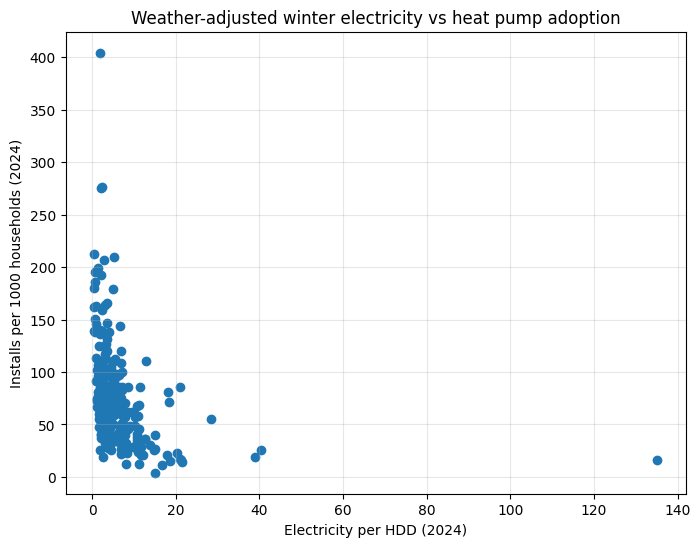

In [56]:
import matplotlib.pyplot as plt

plot_df = final_df[[
    "electricity_per_HDD_2024",
    "installs_per_1000_2024"
]].dropna()

plt.figure(figsize=(8, 6))
plt.scatter(
    plot_df["electricity_per_HDD_2024"],
    plot_df["installs_per_1000_2024"]
)
plt.xlabel("Electricity per HDD (2024)")
plt.ylabel("Installs per 1000 households (2024)")
plt.title("Weather-adjusted winter electricity vs heat pump adoption")
plt.grid(True, alpha=0.3)
plt.show()

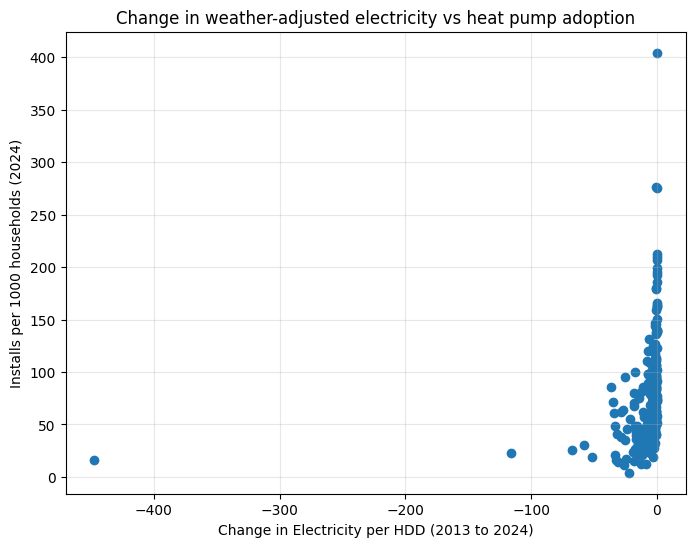

In [57]:
plot_df = final_df[[
    "electricity_per_HDD_change_13_24",
    "installs_per_1000_2024"
]].dropna()

plt.figure(figsize=(8, 6))
plt.scatter(
    plot_df["electricity_per_HDD_change_13_24"],
    plot_df["installs_per_1000_2024"]
)
plt.xlabel("Change in Electricity per HDD (2013 to 2024)")
plt.ylabel("Installs per 1000 households (2024)")
plt.title("Change in weather-adjusted electricity vs heat pump adoption")
plt.grid(True, alpha=0.3)
plt.show()

In [58]:
corr_2024 = final_df[["electricity_per_HDD_2024", "installs_per_1000_2024"]].dropna().corr().iloc[0, 1]
corr_change = final_df[["electricity_per_HDD_change_13_24", "installs_per_1000_2024"]].dropna().corr().iloc[0, 1]

print("Correlation: electricity_per_HDD_2024 vs adoption =", corr_2024)
print("Correlation: change in electricity_per_HDD vs adoption =", corr_change)

Correlation: electricity_per_HDD_2024 vs adoption = -0.28333921237584603
Correlation: change in electricity_per_HDD vs adoption = 0.21145500827018865


In [59]:
winter_2013 = elec_2013[["municipality", "winter_mwh"]].rename(columns={"winter_mwh": "winter_mwh_2013"})
winter_2023 = elec_2023[["municipality", "winter_mwh"]].rename(columns={"winter_mwh": "winter_mwh_2023"})
winter_2024 = elec_2024[["municipality", "winter_mwh"]].rename(columns={"winter_mwh": "winter_mwh_2024"})

In [60]:
final_df = final_df.merge(winter_2013, on="municipality", how="left")
final_df = final_df.merge(winter_2023, on="municipality", how="left")

In [62]:
[col for col in final_df.columns if "winter_mwh" in col.lower()]

['winter_mwh_2024',
 'winter_mwh_2013_x',
 'winter_mwh_2023_x',
 'winter_mwh_2013_y',
 'winter_mwh_2023_y']

In [63]:
final_df[[
    "municipality",
    "winter_mwh_2013_x", "winter_mwh_2013_y",
    "winter_mwh_2023_x", "winter_mwh_2023_y"
]].head(10)

,municipality,winter_mwh_2013_x,winter_mwh_2013_y,winter_mwh_2023_x,winter_mwh_2023_y
0,abington,22940.0,22940.0,11966.0,11966.0
1,acton,48565.0,48565.0,18008.0,18008.0
2,acushnet,9488.0,9488.0,7331.0,7331.0
3,adams,24080.0,24080.0,5845.0,5845.0
4,agawam,61435.0,61435.0,24258.0,24258.0
5,alford,NaN,NaN,1013.0,1013.0
6,amesbury,25449.0,25449.0,11776.0,11776.0
7,amherst,41823.0,41823.0,21022.0,21022.0
8,andover,135104.0,135104.0,26733.0,26733.0
9,aquinnah,584.0,584.0,903.0,903.0


In [64]:
final_df["winter_mwh_2013"] = final_df["winter_mwh_2013_x"].combine_first(final_df["winter_mwh_2013_y"])
final_df["winter_mwh_2023"] = final_df["winter_mwh_2023_x"].combine_first(final_df["winter_mwh_2023_y"])

In [65]:
final_df = final_df.drop(columns=[
    "winter_mwh_2013_x", "winter_mwh_2013_y",
    "winter_mwh_2023_x", "winter_mwh_2023_y"
])

In [66]:
[col for col in final_df.columns if "winter_mwh" in col.lower()]

['winter_mwh_2024', 'winter_mwh_2013', 'winter_mwh_2023']

In [67]:
final_df["electricity_per_HDD_2013"] = final_df["winter_mwh_2013"] / final_df["winter_hdd_2013"]
final_df["electricity_per_HDD_2023"] = final_df["winter_mwh_2023"] / final_df["winter_hdd_2023"]
final_df["electricity_per_HDD_2024"] = final_df["winter_mwh_2024"] / final_df["winter_hdd_2024"]

final_df["electricity_per_HDD_change_13_24"] = (
    final_df["electricity_per_HDD_2024"] - final_df["electricity_per_HDD_2013"]
)

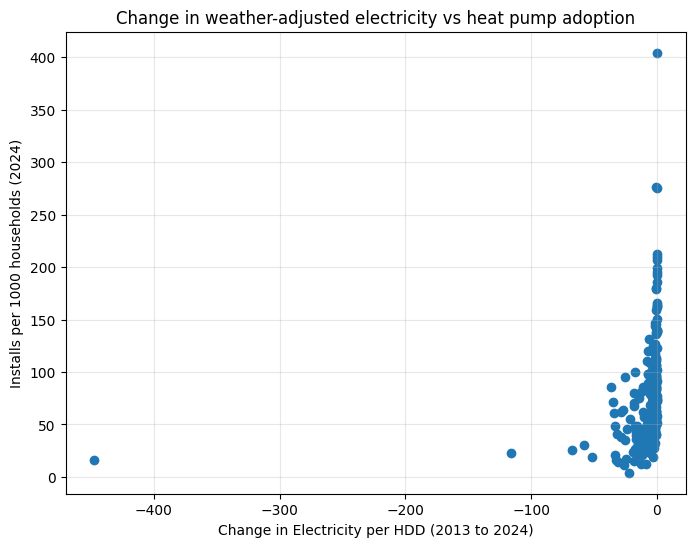

In [68]:
import matplotlib.pyplot as plt

plot_df = final_df[[
    "electricity_per_HDD_change_13_24",
    "installs_per_1000_2024"
]].dropna()

plt.figure(figsize=(8, 6))
plt.scatter(
    plot_df["electricity_per_HDD_change_13_24"],
    plot_df["installs_per_1000_2024"]
)
plt.xlabel("Change in Electricity per HDD (2013 to 2024)")
plt.ylabel("Installs per 1000 households (2024)")
plt.title("Change in weather-adjusted electricity vs heat pump adoption")
plt.grid(True, alpha=0.3)
plt.show()

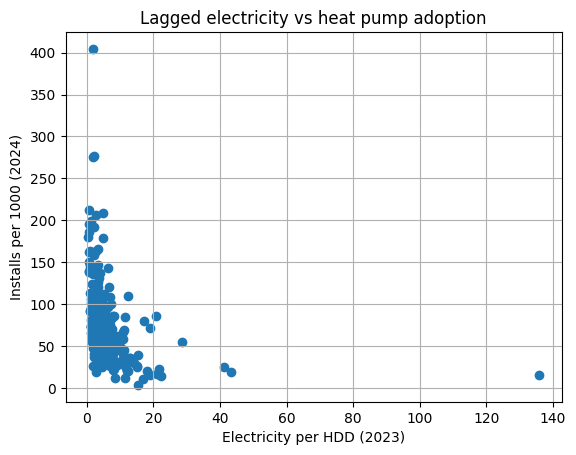

In [69]:
plot_df = final_df[[
    "electricity_per_HDD_2023",
    "installs_per_1000_2024"
]].dropna()

plt.scatter(
    plot_df["electricity_per_HDD_2023"],
    plot_df["installs_per_1000_2024"]
)

plt.xlabel("Electricity per HDD (2023)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("Lagged electricity vs heat pump adoption")
plt.grid(True)
plt.show()

In [71]:
plot_df = final_df[[
    "municipality",
    "electricity_per_HDD_2023",
    "installs_per_1000_2024"
]].dropna()

In [72]:
high_adoption = plot_df[plot_df["installs_per_1000_2024"] > 200]

high_adoption.sort_values("installs_per_1000_2024", ascending=False)

,municipality,electricity_per_HDD_2023,installs_per_1000_2024
299,truro,1.731466,404.360753
241,provincetown,2.281438,276.245767
317,wellfleet,1.971089,275.012083
229,pelham,0.574212,212.686567
89,edgartown,4.818732,209.406495
86,eastham,2.744837,206.839855


In [73]:
high_electricity = plot_df[plot_df["electricity_per_HDD_2023"] > 40]

high_electricity.sort_values("electricity_per_HDD_2023", ascending=False)

,municipality,electricity_per_HDD_2023,installs_per_1000_2024
35,boston,135.842782,15.777735
280,springfield,43.189195,19.265388
347,worcester,41.314808,25.144338


In [74]:
weird_cases = plot_df[
    (plot_df["electricity_per_HDD_2023"] > 40) &
    (plot_df["installs_per_1000_2024"] < 50)
]

weird_cases

,municipality,electricity_per_HDD_2023,installs_per_1000_2024
35,boston,135.842782,15.777735
280,springfield,43.189195,19.265388
347,worcester,41.314808,25.144338


In [75]:
x_thresh = plot_df["electricity_per_HDD_2023"].quantile(0.99)
y_thresh = plot_df["installs_per_1000_2024"].quantile(0.99)

outliers = plot_df[
    (plot_df["electricity_per_HDD_2023"] > x_thresh) |
    (plot_df["installs_per_1000_2024"] > y_thresh)
]

outliers

,municipality,electricity_per_HDD_2023,installs_per_1000_2024
35,boston,135.842782,15.777735
241,provincetown,2.281438,276.245767
280,springfield,43.189195,19.265388
299,truro,1.731466,404.360753
317,wellfleet,1.971089,275.012083
347,worcester,41.314808,25.144338


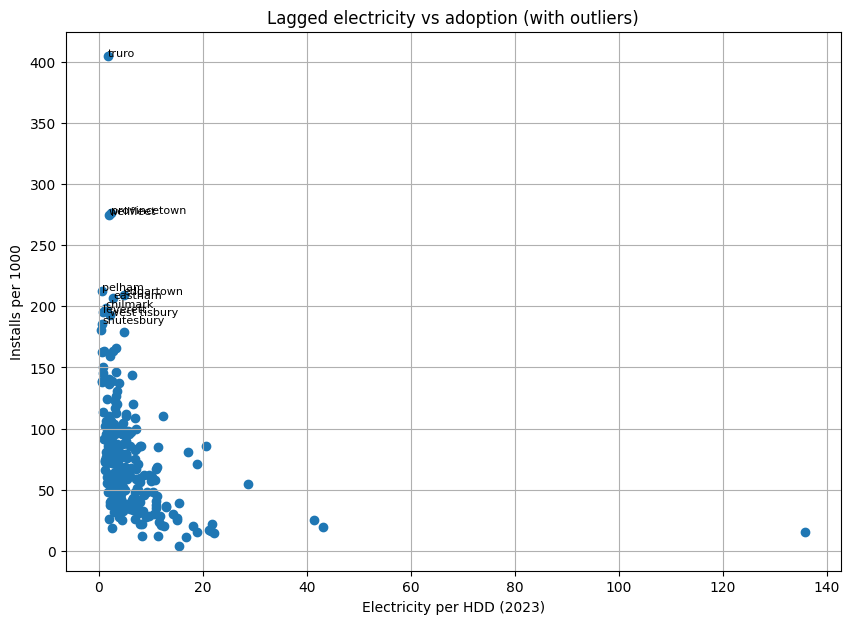

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,7))

plt.scatter(
    plot_df["electricity_per_HDD_2023"],
    plot_df["installs_per_1000_2024"]
)

# label top 10 adoption towns
top_outliers = plot_df.nlargest(10, "installs_per_1000_2024")

for _, row in top_outliers.iterrows():
    plt.text(
        row["electricity_per_HDD_2023"],
        row["installs_per_1000_2024"],
        row["municipality"],
        fontsize=8
    )

plt.xlabel("Electricity per HDD (2023)")
plt.ylabel("Installs per 1000")
plt.title("Lagged electricity vs adoption (with outliers)")
plt.grid(True)
plt.show()

In [70]:
final_df["electricity_per_HDD_change_13_23"]

,electricity_per_HDD_change_13_23
0,-2.901127
1,-8.972668
2,-0.279350
3,-4.775954
4,-10.138638
...,...
346,-28.598985
347,-66.851956
348,-0.029538
349,-4.061689


In [1]:
from google.colab import files
uploaded = files.upload()

Saving final_dataset_with_wsr.csv to final_dataset_with_wsr.csv


In [2]:
import pandas as pd

final_df = pd.read_csv("final_dataset_with_wsr.csv")

final_df.head()

,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,delivered_share_2013,delivered_share_change_13_23,gas_share_change_13_23,electric_share_change_13_23,delivered_share_change_13_24,gas_share_change_13_24,electric_share_change_13_24,wsr_2013,wsr_2023,wsr_2024
0,abington,6438,1053,2774,2484,0.163560,0.430879,0.385834,32.463498,6388,...,0.455329,-0.069495,0.030741,0.038345,-0.087452,0.057439,0.029449,0.917820,0.780765,0.779510
1,acton,9085,1483,4787,2719,0.163236,0.526912,0.299285,85.855806,9409,...,0.327397,-0.028113,0.011168,0.022182,-0.046602,0.004608,0.051952,1.090564,0.916251,0.934947
2,acushnet,4103,148,1758,2020,0.036071,0.428467,0.492323,51.913234,4173,...,0.507937,-0.015614,0.025657,0.016295,-0.028905,0.050581,0.016648,0.714673,0.723335,0.762751
3,adams,4081,333,2156,1507,0.081598,0.528302,0.369272,25.728988,4046,...,0.426721,-0.057448,0.061905,0.038413,-0.068095,0.075126,0.038130,1.018096,1.010372,0.954068
4,agawam,11792,2154,6512,2942,0.182666,0.552239,0.249491,28.154681,11979,...,0.206576,0.042916,-0.021650,-0.003817,0.005045,-0.008399,0.016372,0.835907,0.877038,0.789319


In [3]:
final_df.columns = final_df.columns.str.lower()

final_df["municipality"] = final_df["municipality"].astype(str).str.strip().str.lower()

In [4]:
uploaded = files.upload()

Saving elect_clean_2013.csv to elect_clean_2013.csv


In [5]:
uploaded = files.upload()

Saving elect_clean_2023.csv to elect_clean_2023.csv


In [6]:
uploaded = files.upload()

Saving elec_clean_2024.csv to elec_clean_2024.csv


In [7]:
elec_2013 = pd.read_csv("elect_clean_2013.csv")
elec_2023 = pd.read_csv("elect_clean_2023.csv")
elec_2024 = pd.read_csv("elec_clean_2024.csv")

In [8]:
for df in [elec_2013, elec_2023, elec_2024]:
    df.columns = df.columns.str.lower()
    df["municipality"] = df["municipality"].astype(str).str.strip().str.lower()

In [9]:
winter_2013 = elec_2013[["municipality", "winter_mwh"]].rename(
    columns={"winter_mwh": "winter_mwh_2013"}
)

winter_2023 = elec_2023[["municipality", "winter_mwh"]].rename(
    columns={"winter_mwh": "winter_mwh_2023"}
)

winter_2024 = elec_2024[["municipality", "winter_mwh"]].rename(
    columns={"winter_mwh": "winter_mwh_2024"}
)

In [10]:
final_df = final_df.merge(winter_2013, on="municipality", how="left")
final_df = final_df.merge(winter_2023, on="municipality", how="left")
final_df = final_df.merge(winter_2024, on="municipality", how="left")

In [12]:
from google.colab import files
uploaded = files.upload()

Saving weather_2013.zip to weather_2013.zip


In [13]:
from google.colab import files
uploaded = files.upload()

Saving weather_2023.zip to weather_2023.zip


In [14]:
from google.colab import files
uploaded = files.upload()

Saving weather_2024.zip to weather_2024.zip


In [15]:
import zipfile
import os

zip_files = ["weather_2013.zip", "weather_2023.zip", "weather_2024.zip"]

for z in zip_files:
    with zipfile.ZipFile(z, "r") as zip_ref:
        zip_ref.extractall(z.replace(".zip", ""))

print(os.listdir("weather_2013"))
print(os.listdir("weather_2023"))
print(os.listdir("weather_2024"))

['boston_2013_jan.nc', 'springfield_2013_feb.nc', 'worcester_2013_mar.nc', 'pittsfield_2013_feb.nc', 'springfield_2013_mar.nc', 'boston_2013_mar.nc', 'worcester_2013_feb.nc', 'worcester_2013_jan.nc', 'boston_2013_feb.nc', 'springfield_2013_jan.nc', 'pittsfield_2013_jan.nc', 'pittsfield_2013_mar.nc']
['pittsfield_2023_jan.nc', 'worcester_2023_mar.nc', 'springfield_2023_jan.nc', 'boston_2023_jan.nc', 'springfield_2023_feb.nc', 'boston_2023_feb.nc', 'boston_2023_mar.nc', 'pittsfield_2023_mar.nc', 'pittsfield_2023_feb.nc', 'springfield_2023_mar.nc', 'worcester_2023_feb.nc', 'worcester_2023_jan.nc']
['pittsfield_mar_2024.nc', 'springfield_jan_2024.nc', 'pittsfield_jan_2024.nc', 'springfield_mar_2024.nc', 'boston_mar_2024.nc', 'boston_jan_2024.nc', 'worcester_mar-2024.nc', 'worcester_jan_2024.nc', 'boston_feb_2024.nc', 'pittsfield_feb_2024.nc', 'springfield_feb_2024.nc', 'worcester_feb_2024.nc']


In [16]:
import xarray as xr
import pandas as pd
import numpy as np
import os

In [17]:
def compute_hdd_from_nc(file_path):
    ds = xr.open_dataset(file_path)

    possible_temp_vars = ["t2m", "temperature_c", "2m_temperature"]
    temp_var = None
    for v in possible_temp_vars:
        if v in ds.data_vars:
            temp_var = v
            break

    if temp_var is None:
        raise ValueError(f"No temp variable found in {file_path}. Found: {list(ds.data_vars)}")

    df = ds[temp_var].to_dataframe().reset_index()

    possible_time_cols = ["time", "valid_time"]
    time_col = None
    for c in possible_time_cols:
        if c in df.columns:
            time_col = c
            break

    if time_col is None:
        raise ValueError(f"No time column found in {file_path}. Found: {df.columns.tolist()}")

    df[time_col] = pd.to_datetime(df[time_col])

    # ERA5 t2m is usually Kelvin
    if temp_var in ["t2m", "2m_temperature"]:
        df["temp_f"] = (df[temp_var] - 273.15) * 9/5 + 32
    else:
        df["temp_f"] = df[temp_var] * 9/5 + 32

    df["date"] = df[time_col].dt.date
    daily = df.groupby("date", as_index=False)["temp_f"].mean()

    daily["hdd"] = (65 - daily["temp_f"]).clip(lower=0)

    return daily["hdd"].sum()

In [18]:
def compute_winter_hdd_for_folder(folder_path, year):
    results = []

    for fname in os.listdir(folder_path):
        if fname.endswith(".nc"):
            file_path = os.path.join(folder_path, fname)

            region = fname.split("_")[0].lower()
            hdd = compute_hdd_from_nc(file_path)

            results.append({
                "region": region,
                "year": year,
                "file": fname,
                "monthly_hdd": hdd
            })

    df = pd.DataFrame(results)

    winter_hdd = df.groupby(["region", "year"], as_index=False)["monthly_hdd"].sum()
    winter_hdd = winter_hdd.rename(columns={"monthly_hdd": "winter_hdd"})

    return df, winter_hdd

In [19]:
monthly_2013, winter_2013 = compute_winter_hdd_for_folder("weather_2013", 2013)
monthly_2023, winter_2023 = compute_winter_hdd_for_folder("weather_2023", 2023)
monthly_2024, winter_2024 = compute_winter_hdd_for_folder("weather_2024", 2024)

winter_hdd_all = pd.concat([winter_2013, winter_2023, winter_2024], ignore_index=True)

winter_hdd_all

,region,year,winter_hdd
0,boston,2013,3048.163818
1,pittsfield,2013,3603.442383
2,springfield,2013,3199.531006
3,worcester,2013,3261.205078
4,boston,2023,2587.402832
5,pittsfield,2023,3065.754395
6,springfield,2023,2676.711182
7,worcester,2023,2752.475586
8,boston,2024,2732.610596
9,pittsfield,2024,3117.519531


In [21]:
from google.colab import files
files.download("winter_hdd_all.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
winter_hdd_all.to_csv("winter_hdd_all.csv", index=False)

In [25]:
towns = sorted(final_df["municipality"].dropna().astype(str).str.strip().str.lower().unique())
len(towns)

351

In [26]:
from geopy.geocoders import Nominatim
import pandas as pd
import time

geolocator = Nominatim(user_agent="ma_heat_pump_analysis")

rows = []

for town in towns:
    query = f"{town}, Massachusetts, USA"

    try:
        location = geolocator.geocode(query, timeout=10)

        if location is not None:
            rows.append({
                "municipality": town,
                "latitude": location.latitude,
                "longitude": location.longitude
            })
        else:
            rows.append({
                "municipality": town,
                "latitude": None,
                "longitude": None
            })
    except:
        rows.append({
            "municipality": town,
            "latitude": None,
            "longitude": None
        })

    time.sleep(1)  # IMPORTANT (avoid blocking)

town_coords = pd.DataFrame(rows)

town_coords.head()

,municipality,latitude,longitude
0,abington,42.104823,-70.945322
1,acton,42.485093,-71.432840
2,acushnet,41.680659,-70.907816
3,adams,42.620943,-73.120413
4,agawam,42.068862,-72.615160


In [27]:
from geopy.distance import geodesic

regions = {
    "boston": ((42.5 + 42.2)/2, (-71.2 + -70.9)/2),
    "worcester": ((42.4 + 42.1)/2, (-72.0 + -71.6)/2),
    "springfield": ((42.2 + 41.9)/2, (-72.8 + -72.4)/2),
    "pittsfield": ((42.6 + 42.3)/2, (-73.4 + -73.1)/2)
}

In [28]:
def get_nearest_region(lat, lon):
    if pd.isna(lat) or pd.isna(lon):
        return None

    distances = {
        region: geodesic((lat, lon), coords).miles
        for region, coords in regions.items()
    }

    return min(distances, key=distances.get)

town_coords["region"] = town_coords.apply(
    lambda row: get_nearest_region(row["latitude"], row["longitude"]),
    axis=1
)

town_region_map = town_coords[["municipality", "region"]]

town_region_map.head()

,municipality,region
0,abington,boston
1,acton,boston
2,acushnet,boston
3,adams,pittsfield
4,agawam,springfield


In [29]:
final_df["municipality"] = final_df["municipality"].str.strip().str.lower()

final_df = final_df.merge(
    town_region_map,
    on="municipality",
    how="left"
)

In [30]:
final_df[["municipality", "region"]].head()
final_df["region"].isna().sum()

np.int64(0)

In [31]:
town_region_map.to_csv("town_region_map.csv", index=False)

In [32]:
final_df = final_df.merge(hdd_2013, on="region", how="left")
final_df = final_df.merge(hdd_2023, on="region", how="left")
final_df = final_df.merge(hdd_2024, on="region", how="left")

In [33]:
[col for col in final_df.columns if "winter_hdd" in col]

['winter_hdd_2013', 'winter_hdd_2023', 'winter_hdd_2024']

In [34]:
final_df["electricity_per_HDD_2013"] = final_df["winter_mwh_2013"] / final_df["winter_hdd_2013"]

final_df["electricity_per_HDD_2023"] = final_df["winter_mwh_2023"] / final_df["winter_hdd_2023"]

final_df["electricity_per_HDD_2024"] = final_df["winter_mwh_2024"] / final_df["winter_hdd_2024"]

In [35]:
final_df["electricity_per_HDD_change_13_23"] = (
    final_df["electricity_per_HDD_2023"] - final_df["electricity_per_HDD_2013"]
)

final_df["electricity_per_HDD_change_13_24"] = (
    final_df["electricity_per_HDD_2024"] - final_df["electricity_per_HDD_2013"]
)

In [36]:
final_df.head()
final_df.shape

(351, 49)

In [37]:
final_df.isna().sum()

,0
municipality,0
total_households_2023,0
electric_fuel_2023,0
gas_fuel_2023,0
delivered_fuels_2023,0
electric_share_2023,0
gas_share_2023,0
delivered_share_2023,0
installs_per_1000_2023,103
total_households_2024,0


In [38]:
final_df.to_csv("final_dataset_complete.csv", index=False)

In [39]:
from google.colab import files
files.download("final_dataset_complete.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
towns_list = [
    "granby", "rutland", "holland", "hubbardston", "dunstable",
    "hampden", "otis", "west brookfield", "sturbridge", "sheffield"
]

In [41]:
subset = final_df[
    final_df["municipality"].isin(towns_list)
][[
    "municipality",
    "delivered_share_2013",
    "delivered_share_2024",
    "delivered_share_change_13_24",
    "installs_per_1000_2024"
]].sort_values("installs_per_1000_2024", ascending=False)

subset

,municipality,delivered_share_2013,delivered_share_2024,delivered_share_change_13_24,installs_per_1000_2024
224,otis,0.618574,0.706304,0.087730,163.323782
286,sturbridge,0.632575,0.703094,0.070520,131.139489
81,dunstable,0.615520,0.707252,0.091731,102.059087
256,rutland,0.703704,0.825746,0.122042,94.505495
134,holland,0.595870,0.713564,0.117693,91.828138
110,granby,0.664704,0.815166,0.150462,85.738906
266,sheffield,0.712995,0.780136,0.067141,81.122062
139,hubbardston,0.689928,0.800712,0.110784,74.139976
322,west brookfield,0.572115,0.653134,0.081019,66.268657
119,hampden,0.413522,0.501799,0.088277,55.526992


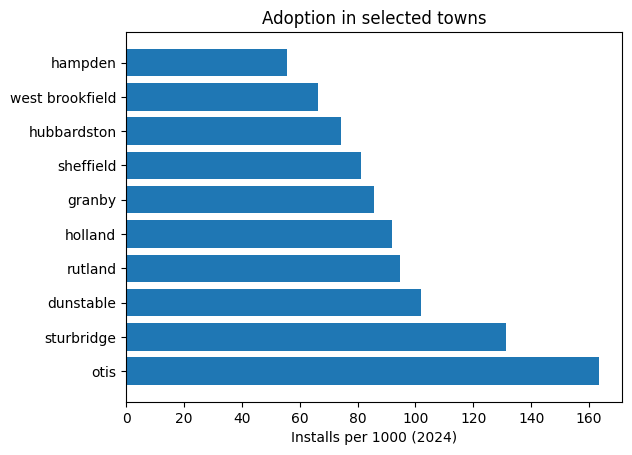

In [42]:
import matplotlib.pyplot as plt

subset = subset.dropna(subset=["installs_per_1000_2024"])

plt.barh(
    subset["municipality"],
    subset["installs_per_1000_2024"]
)

plt.xlabel("Installs per 1000 (2024)")
plt.title("Adoption in selected towns")
plt.show()

In [43]:
filtered_towns = final_df[
    (final_df["delivered_share_change_13_24"] < 0) &   # oil decreased
    (final_df["installs_per_1000_2024"].notna()) &     # adoption exists
    (final_df["installs_per_1000_2024"] < 100)         # not high adoption
][[
    "municipality",
    "delivered_share_2013",
    "delivered_share_2024",
    "delivered_share_change_13_24",
    "gas_share_2024",
    "installs_per_1000_2024"
]].sort_values("delivered_share_change_13_24")

In [44]:
filtered_towns.head(20)

,municipality,delivered_share_2013,delivered_share_2024,delivered_share_change_13_24,gas_share_2024,installs_per_1000_2024
46,brookline,0.318821,0.115779,-0.203041,0.602530,20.988147
196,nantucket,0.748833,0.563595,-0.185238,0.096535,58.263519
167,marblehead,0.351916,0.189890,-0.162026,0.736639,21.474243
198,needham,0.460690,0.304937,-0.155753,0.556447,62.143967
28,berlin,0.689788,0.536973,-0.152815,0.277816,73.946095
283,stoneham,0.464935,0.318186,-0.146749,0.443122,39.901528
208,north adams,0.422710,0.277404,-0.145306,0.557666,19.166106
138,hopkinton,0.509661,0.364414,-0.145246,0.542793,95.645646
30,beverly,0.421549,0.278269,-0.143280,0.502827,48.527680
242,quincy,0.291292,0.148658,-0.142633,0.543602,16.473446


In [47]:
len(filtered_towns)

181

In [48]:
filtered_towns.sort_values("gas_share_2024", ascending=False).head(10)

,municipality,delivered_share_2013,delivered_share_2024,delivered_share_change_13_24,gas_share_2024,installs_per_1000_2024
158,longmeadow,0.171503,0.102737,-0.068766,0.813722,52.257376
95,fall river,0.109572,0.073587,-0.035985,0.792027,11.311948
200,new bedford,0.146079,0.091268,-0.054810,0.788933,20.581486
350,yarmouth,0.140389,0.115938,-0.024451,0.775741,86.053909
56,chelmsford,0.139367,0.101561,-0.037806,0.770781,48.475836
272,somerset,0.197449,0.187055,-0.010394,0.747281,34.913388
167,marblehead,0.351916,0.189890,-0.162026,0.736639,21.474243
291,swansea,0.279766,0.209426,-0.070340,0.723711,39.469809
171,mashpee,0.158709,0.124036,-0.034673,0.718570,96.986685
31,billerica,0.238092,0.193588,-0.044504,0.712166,35.285770


In [49]:
final_df.groupby(
    (final_df["gas_share_2024"] > 0.7)
)["installs_per_1000_2024"].mean()

,installs_per_1000_2024
gas_share_2024,
False,74.779032
True,51.529351


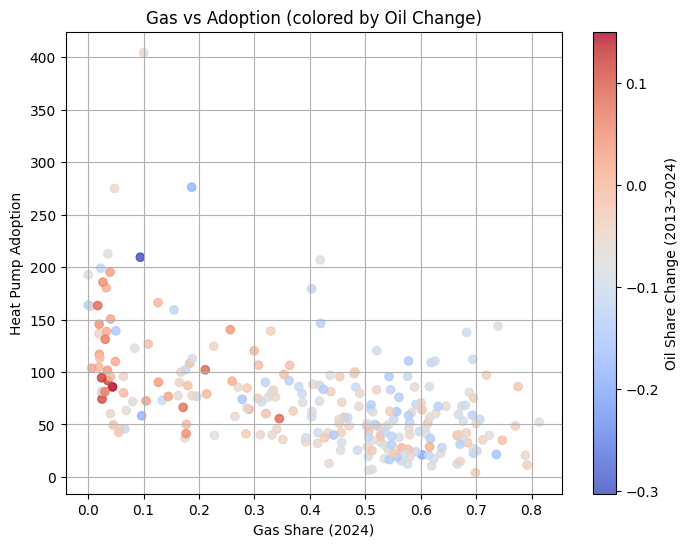

In [50]:
plt.figure(figsize=(8,6))

plt.scatter(
    final_df["gas_share_2024"],
    final_df["installs_per_1000_2024"],
    c=final_df["delivered_share_change_13_24"],  # oil change
    cmap="coolwarm",
    alpha=0.8
)

plt.colorbar(label="Oil Share Change (2013–2024)")

plt.xlabel("Gas Share (2024)")
plt.ylabel("Heat Pump Adoption")
plt.title("Gas vs Adoption (colored by Oil Change)")

plt.grid(True)
plt.show()

/tmp/ipykernel_58612/2628485741.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = final_df.groupby("gas_bucket")["installs_per_1000_2024"].mean()


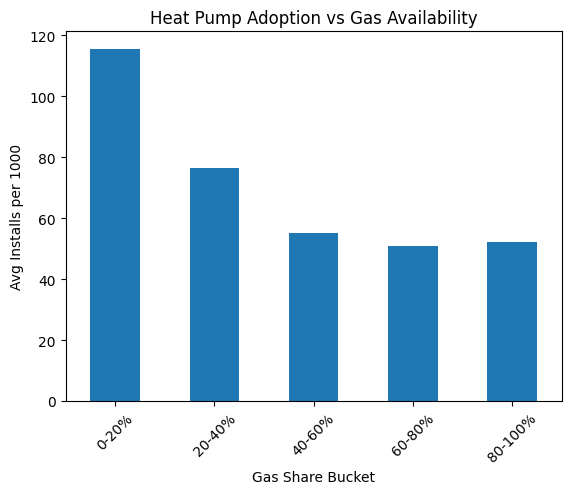

In [51]:
import pandas as pd

# create gas buckets
final_df["gas_bucket"] = pd.cut(
    final_df["gas_share_2024"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1],
    labels=["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"]
)

grouped = final_df.groupby("gas_bucket")["installs_per_1000_2024"].mean()

grouped.plot(kind="bar")

plt.ylabel("Avg Installs per 1000")
plt.xlabel("Gas Share Bucket")
plt.title("Heat Pump Adoption vs Gas Availability")

plt.xticks(rotation=45)
plt.show()

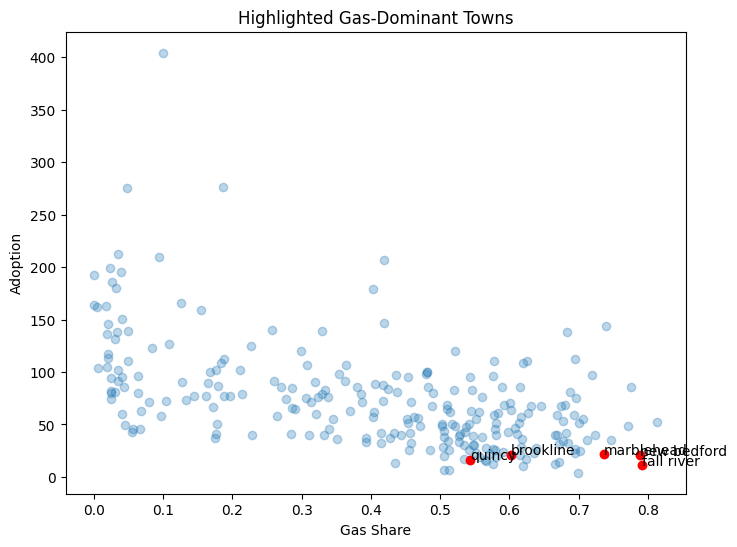

In [52]:
highlight = [
    "brookline", "marblehead", "quincy",
    "fall river", "new bedford"
]

subset = final_df[final_df["municipality"].isin(highlight)]

plt.figure(figsize=(8,6))

plt.scatter(final_df["gas_share_2024"], final_df["installs_per_1000_2024"], alpha=0.3)

plt.scatter(
    subset["gas_share_2024"],
    subset["installs_per_1000_2024"],
    color="red"
)

for i, row in subset.iterrows():
    plt.text(row["gas_share_2024"], row["installs_per_1000_2024"], row["municipality"])

plt.xlabel("Gas Share")
plt.ylabel("Adoption")
plt.title("Highlighted Gas-Dominant Towns")

plt.show()

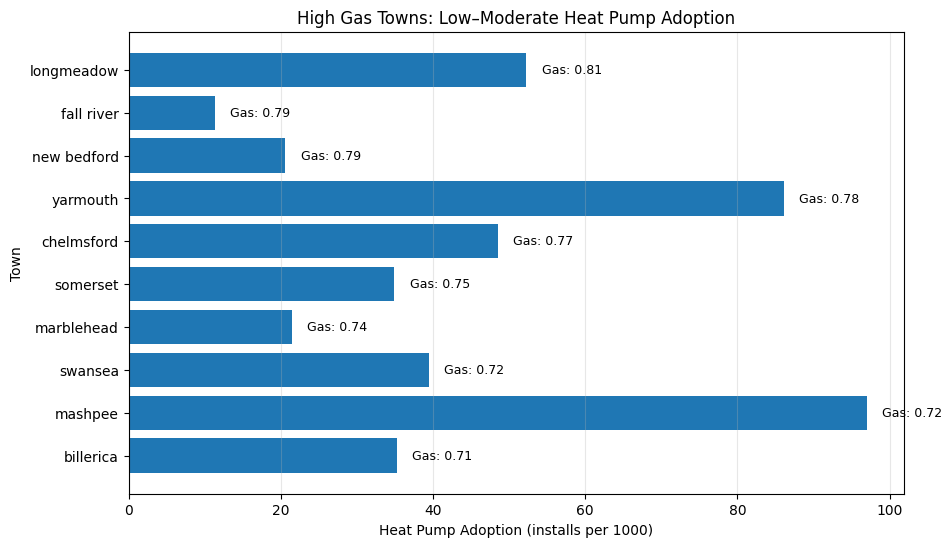

In [53]:
import matplotlib.pyplot as plt

# your subset (assuming it's already filtered as shown)
subset = final_df[
    final_df["municipality"].isin([
        "longmeadow", "fall river", "new bedford", "yarmouth",
        "chelmsford", "somerset", "marblehead", "swansea",
        "mashpee", "billerica"
    ])
].copy()

subset = subset.sort_values("gas_share_2024")

plt.figure(figsize=(10,6))

bars = plt.barh(
    subset["municipality"],
    subset["installs_per_1000_2024"]
)

plt.xlabel("Heat Pump Adoption (installs per 1000)")
plt.ylabel("Town")
plt.title("High Gas Towns: Low–Moderate Heat Pump Adoption")

plt.grid(axis="x", alpha=0.3)

# annotate gas share on bars
for i, row in subset.iterrows():
    plt.text(
        row["installs_per_1000_2024"] + 2,
        row["municipality"],
        f"Gas: {row['gas_share_2024']:.2f}",
        va="center",
        fontsize=9
    )

plt.show()

---
## Original analysis section: `cooling_degree_days.ipynb`

**What this section contains:** Cooling-degree-day processing and CDD-normalized summer electricity feature construction.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [1]:
from google.colab import files
uploaded = files.upload()

Saving summer_2013.zip to summer_2013.zip


In [2]:
from google.colab import files
uploaded = files.upload()

Saving summer_2023.zip to summer_2023.zip


In [3]:
from google.colab import files
uploaded = files.upload()

Saving summer_2024.zip to summer_2024.zip


In [4]:
import zipfile, os

zip_files = ["summer_2013.zip", "summer_2023.zip", "summer_2024.zip"]

for z in zip_files:
    folder = z.replace(".zip", "")
    os.makedirs(folder, exist_ok=True)

    with zipfile.ZipFile(z, 'r') as zip_ref:
        zip_ref.extractall(folder)

print("All files extracted")

All files extracted


In [5]:
import xarray as xr
import pandas as pd
import numpy as np
import glob

In [6]:
def compute_cdd(file_path):
    ds = xr.open_dataset(file_path)

    # temperature variable
    temp = ds["t2m"]

    # convert to Fahrenheit
    temp_f = (temp - 273.15) * 9/5 + 32

    # detect time column
    time_dim = "time" if "time" in temp_f.dims else "valid_time"

    # daily avg temp
    daily_avg = temp_f.resample({time_dim: "1D"}).mean()

    # CDD formula
    daily_cdd = xr.where(daily_avg > 65, daily_avg - 65, 0)

    # SUM over summer
    total_cdd = daily_cdd.sum(dim=time_dim)

    # average over region grid
    return float(total_cdd.mean().values)

In [7]:
def get_region(file):
    f = file.lower()
    if "boston" in f: return "Boston"
    if "worcester" in f: return "Worcester"
    if "springfield" in f: return "Springfield"
    if "pittsfield" in f: return "Pittsfield"
    return "Unknown"

In [10]:
results = []

In [11]:
import glob, os

for year in [2013, 2023, 2024]:
    folder = f"summer_{year}"
    files = glob.glob(f"{folder}/*.nc")

    print(f"\nProcessing {year}, files found:", len(files))  # DEBUG

    for f in files:
        region = get_region(f)
        cdd = compute_cdd(f)

        print(region, year, cdd)  # DEBUG (you should see values)

        results.append({
            "region": region,
            "year": year,
            "summer_cdd": cdd
        })


Processing 2013, files found: 12
Worcester 2013 310.9073181152344
Boston 2013 113.90361785888672
Worcester 2013 100.88243865966797
Boston 2013 85.3618392944336
Boston 2013 243.0701446533203
Springfield 2013 110.34391784667969
Pittsfield 2013 213.04025268554688
Springfield 2013 323.2313232421875
Pittsfield 2013 65.59659576416016
Pittsfield 2013 66.03694152832031
Springfield 2013 150.31553649902344
Worcester 2013 141.71804809570312

Processing 2023, files found: 12
Boston 2023 52.706451416015625
Boston 2023 113.65315246582031
Unknown 2023 253.6027374267578
Springfield 2023 124.2686538696289
Pittsfield 2023 54.73640823364258
Springfield 2023 62.153892517089844
Boston 2023 226.68763732910156
Pittsfield 2023 37.86540603637695
Pittsfield 2023 174.4833221435547
Unknown 2023 253.6027374267578
Unknown 2023 63.20128631591797
Springfield 2023 259.7349853515625

Processing 2024, files found: 12
Unknown 2024 144.28378295898438
Pittsfield 2024 120.88975524902344
Pittsfield 2024 226.45114135742188
B

In [12]:
print(len(results))
print(results[:5])

36
[{'region': 'Worcester', 'year': 2013, 'summer_cdd': 310.9073181152344}, {'region': 'Boston', 'year': 2013, 'summer_cdd': 113.90361785888672}, {'region': 'Worcester', 'year': 2013, 'summer_cdd': 100.88243865966797}, {'region': 'Boston', 'year': 2013, 'summer_cdd': 85.3618392944336}, {'region': 'Boston', 'year': 2013, 'summer_cdd': 243.0701446533203}]


In [13]:
cdd_df = pd.DataFrame(results)
cdd_df

,region,year,summer_cdd
0,Worcester,2013,310.907318
1,Boston,2013,113.903618
2,Worcester,2013,100.882439
3,Boston,2013,85.361839
4,Boston,2013,243.070145
5,Springfield,2013,110.343918
6,Pittsfield,2013,213.040253
7,Springfield,2013,323.231323
8,Pittsfield,2013,65.596596
9,Pittsfield,2013,66.036942


In [14]:
# remove Unknown first after fixing get_region
cdd_df = cdd_df[cdd_df["region"] != "Unknown"]

# sum Jun + Jul + Aug for each region/year
cdd_grouped = (
    cdd_df
    .groupby(["region", "year"], as_index=False)["summer_cdd"]
    .sum()
)

cdd_grouped

,region,year,summer_cdd
0,Boston,2013,442.335602
1,Boston,2023,393.047241
2,Boston,2024,512.838081
3,Pittsfield,2013,344.673790
4,Pittsfield,2023,267.085136
5,Pittsfield,2024,448.845833
6,Springfield,2013,583.890778
7,Springfield,2023,446.157532
8,Springfield,2024,640.492828
9,Worcester,2013,553.507805


In [15]:
cdd_final = cdd_grouped.pivot(
    index="region",
    columns="year",
    values="summer_cdd"
).reset_index()

cdd_final.columns = [
    "region",
    "summer_cdd_2013",
    "summer_cdd_2023",
    "summer_cdd_2024"
]

cdd_final

,region,summer_cdd_2013,summer_cdd_2023,summer_cdd_2024
0,Boston,442.335602,393.047241,512.838081
1,Pittsfield,344.673790,267.085136,448.845833
2,Springfield,583.890778,446.157532,640.492828
3,Worcester,553.507805,NaN,NaN


In [16]:
import glob, os

for folder in ["summer_2023", "summer_2024"]:
    print(folder)
    for f in glob.glob(f"{folder}/*.nc"):
        print(os.path.basename(f))

summer_2023
boston_2023_jun.nc
boston_2023_aug.nc
worcestor_2023_july.nc
springfield_2023_aug.nc
pittsfield_2023_aug.nc
springfield_2023_jun.nc
boston_2023_july.nc
pittsfield_2023_jun.nc
pittsfield_2023_july.nc
worcestor_2023_aug.nc
worcestor_2023_jun.nc
springfield_2023_july.nc
summer_2024
worcestor_2024_jun.nc
pittsfield_2024_jun.nc
pittsfield_2024_july.nc
boston_2024_jun.nc
pittsfield_2024_aug.nc
worcestor_2024_aug.nc
springfield_2024_july.nc
springfield_2024_jun.nc
boston_2024_july.nc
boston_2024_aug.nc
worcestor_2024_july.nc
springfield_2024_aug.nc


In [17]:
def get_region(file):
    f = file.lower()

    if "boston" in f:
        return "Boston"
    elif "worcester" in f or "worcestor" in f:
        return "Worcester"
    elif "springfield" in f:
        return "Springfield"
    elif "pittsfield" in f:
        return "Pittsfield"
    else:
        return "Unknown"

In [18]:
results = []

for year in [2013, 2023, 2024]:
    folder = f"summer_{year}"
    files = glob.glob(f"{folder}/*.nc")

    for f in files:
        region = get_region(f)
        cdd = compute_cdd(f)

        results.append({
            "region": region,
            "year": year,
            "summer_cdd": cdd
        })

cdd_df = pd.DataFrame(results)

cdd_grouped = (
    cdd_df
    .groupby(["region", "year"], as_index=False)["summer_cdd"]
    .sum()
)

cdd_final = cdd_grouped.pivot(
    index="region",
    columns="year",
    values="summer_cdd"
).reset_index()

cdd_final.columns = ["region", "summer_cdd_2013", "summer_cdd_2023", "summer_cdd_2024"]

cdd_final

,region,summer_cdd_2013,summer_cdd_2023,summer_cdd_2024
0,Boston,442.335602,393.047241,512.838081
1,Pittsfield,344.673790,267.085136,448.845833
2,Springfield,583.890778,446.157532,640.492828
3,Worcester,553.507805,570.406761,584.684402


In [19]:
cdd_final.to_csv("regional_summer_cdd_2013_2023_2024.csv", index=False)

In [20]:
from google.colab import files
files.download("regional_summer_cdd_2013_2023_2024.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
from google.colab import files
uploaded = files.upload()

Saving final_dataset_clean.csv to final_dataset_clean.csv


In [23]:
import pandas as pd

final_df = pd.read_csv("final_dataset_clean.csv")
final_df.head()

,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,winter_hdd_2023,winter_hdd_2024,electricity_per_HDD_2013,electricity_per_HDD_2023,electricity_per_HDD_2024,electricity_per_HDD_change_13_23,electricity_per_HDD_change_13_24,elec_per_hh_per_hdd_2023,installs_per_1000_full_disp_2024,hp_accounts_full_disp_2024
0,wellfleet,1924,236,72,1400,0.122661,0.037422,0.727651,295.738046,2069,...,2587.4028,2732.6106,1.833891,1.971089,2.136419,0.137198,0.302528,0.001024,66.698888,138.0
1,oak bluffs,2064,259,167,1424,0.125484,0.080911,0.689922,156.492248,1944,...,2587.4028,2732.6106,3.807210,3.348532,3.594731,-0.458679,-0.212479,0.001622,56.069959,109.0
2,tisbury,1886,293,0,1437,0.155355,0.000000,0.761930,165.959703,1912,...,2587.4028,2732.6106,3.017226,2.727059,3.034827,-0.290167,0.017601,0.001446,53.870293,103.0
3,eastham,2860,463,1170,1214,0.161888,0.409091,0.424476,219.930070,3041,...,2587.4028,2732.6106,2.986716,2.744837,2.956513,-0.241879,-0.030203,0.000960,49.325880,150.0
4,dennis,7116,1181,4878,1016,0.165964,0.685497,0.142777,147.414278,7302,...,2587.4028,2732.6106,8.066168,6.397535,6.726169,-1.668633,-1.339999,0.000899,34.237195,250.0


In [24]:
final_df.columns

Index(['municipality', 'total_households_2023', 'electric_fuel_2023',
       'gas_fuel_2023', 'delivered_fuels_2023', 'electric_share_2023',
       'gas_share_2023', 'delivered_share_2023', 'installs_per_1000_2023',
       'total_households_2024', 'electric_fuel_2024', 'gas_fuel_2024',
       'delivered_fuels_2024', 'electric_share_2024', 'gas_share_2024',
       'delivered_share_2024', 'installs_per_1000_2024',
       'electric_share_change_23_24', 'gas_share_change_23_24',
       'delivered_share_change_23_24', 'adoption_change_23_24',
       'total_households_2013', 'electric_fuel_2013', 'gas_fuel_2013',
       'delivered_fuels_2013', 'electric_share_2013', 'gas_share_2013',
       'delivered_share_2013', 'delivered_share_change_13_23',
       'gas_share_change_13_23', 'electric_share_change_13_23',
       'delivered_share_change_13_24', 'gas_share_change_13_24',
       'electric_share_change_13_24', 'wsr_2013', 'wsr_2023', 'wsr_2024',
       'winter_mwh_2013', 'winter_mwh_2023', 'w

In [25]:
[col for col in final_df.columns if "summer" in col.lower()]

[]

In [26]:
final_df["region"] = final_df["region"].str.lower()
cdd_final["region"] = cdd_final["region"].str.lower()

In [27]:
final_df = final_df.merge(cdd_final, on="region", how="left")

In [28]:
final_df[["municipality", "region", "summer_cdd_2023"]].head()

,municipality,region,summer_cdd_2023
0,wellfleet,boston,393.047241
1,oak bluffs,boston,393.047241
2,tisbury,boston,393.047241
3,eastham,boston,393.047241
4,dennis,boston,393.047241


In [29]:
from google.colab import files
uploaded = files.upload()

Saving elect_clean_2013.csv to elect_clean_2013.csv


In [30]:
from google.colab import files
uploaded = files.upload()

Saving elect_clean_2023.csv to elect_clean_2023.csv


In [31]:
from google.colab import files
uploaded = files.upload()

Saving elect_clean_2024.csv to elect_clean_2024.csv


In [32]:
import pandas as pd

df_2013 = pd.read_csv("elect_clean_2013.csv")
df_2023 = pd.read_csv("elect_clean_2023.csv")
df_2024 = pd.read_csv("elect_clean_2024.csv")

In [34]:
for df in [df_2013, df_2023, df_2024]:
    df.columns = df.columns.str.lower().str.strip()

In [35]:
for df in [df_2013, df_2023, df_2024]:
    df["municipality"] = df["municipality"].str.lower().str.strip()

In [36]:
df_2023.columns

Index(['municipality', 'jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug',
       'sep', 'oct', 'nov', 'dec', 'total', 'winter_mwh', 'summer_mwh',
       'winter_summer_ratio', 'highest_winter_month_mwh',
       'highest_winter_month_name'],
      dtype='object')

In [37]:
df_2023[["municipality", "summer_mwh"]]

,municipality,summer_mwh
0,hancock,868
1,windsor,612
2,sandisfield,1164
3,plainfield,466
4,cummington,637
...,...,...
296,harwich,21650
297,nantucket,44416
298,mashpee,26418
299,dennis,28066


In [38]:
df_2013 = df_2013[["municipality", "summer_mwh"]].rename(columns={"summer_mwh": "summer_mwh_2013"})
df_2023 = df_2023[["municipality", "summer_mwh"]].rename(columns={"summer_mwh": "summer_mwh_2023"})
df_2024 = df_2024[["municipality", "summer_mwh"]].rename(columns={"summer_mwh": "summer_mwh_2024"})

In [39]:
final_df = final_df.merge(df_2013, on="municipality", how="left")
final_df = final_df.merge(df_2023, on="municipality", how="left")
final_df = final_df.merge(df_2024, on="municipality", how="left")

In [40]:
final_df[[
    "municipality",
    "summer_mwh_2013",
    "summer_mwh_2023",
    "summer_mwh_2024"
]].head(10)

,municipality,summer_mwh_2013,summer_mwh_2023,summer_mwh_2024
0,wellfleet,8392.0,7541.0,7196.0
1,oak bluffs,16166.0,10619.0,10730.0
2,tisbury,12022.0,8039.0,8265.0
3,eastham,12955.0,11216.0,11202.0
4,dennis,38766.0,28066.0,29116.0
5,rutland,9059.0,7011.0,7247.0
6,brewster,23143.0,16617.0,16852.0
7,sandwich,46678.0,23382.0,23497.0
8,falmouth,87163.0,49828.0,49819.0
9,southborough,26457.0,11566.0,12295.0


In [41]:
set(final_df["municipality"]) - set(df_2023["municipality"])

{'ashburnham',
 'belmont',
 'berkley',
 'boxborough',
 'boylston',
 'braintree',
 'chester',
 'chicopee',
 'concord',
 'danvers',
 'dighton',
 'georgetown',
 'gosnold',
 'groton',
 'groveland',
 'hingham',
 'holden',
 'holyoke',
 'hudson',
 'hull',
 'ipswich',
 'lakeville',
 'littleton',
 'lynnfield',
 'mansfield',
 'marblehead',
 'merrimac',
 'middleborough',
 'middleton',
 'north attleborough',
 'north reading',
 'norwood',
 'paxton',
 'peabody',
 'princeton',
 'raynham',
 'reading',
 'rowley',
 'russell',
 'shrewsbury',
 'south hadley',
 'sterling',
 'stow',
 'taunton',
 'templeton',
 'wakefield',
 'wellesley',
 'west boylston',
 'westfield',
 'wilmington'}

In [42]:
final_df["municipality"] = final_df["municipality"].str.lower().str.strip()

In [43]:
final_df["region"] = final_df["region"].str.lower()
cdd_final["region"] = cdd_final["region"].str.lower()

final_df = final_df.merge(cdd_final, on="region", how="left")

In [45]:
[col for col in final_df.columns if "cdd" in col.lower()]

['summer_cdd_2013_x',
 'summer_cdd_2023_x',
 'summer_cdd_2024_x',
 'summer_cdd_2013_y',
 'summer_cdd_2023_y',
 'summer_cdd_2024_y']

In [46]:
final_df = final_df.drop(columns=[
    "summer_cdd_2013_y",
    "summer_cdd_2023_y",
    "summer_cdd_2024_y"
])

final_df = final_df.rename(columns={
    "summer_cdd_2013_x": "summer_cdd_2013",
    "summer_cdd_2023_x": "summer_cdd_2023",
    "summer_cdd_2024_x": "summer_cdd_2024"
})

In [47]:
[col for col in final_df.columns if "cdd" in col.lower()]

['summer_cdd_2013', 'summer_cdd_2023', 'summer_cdd_2024']

In [48]:
final_df["elec_per_hh_per_cdd_2023"] = (
    final_df["summer_mwh_2023"] /
    (final_df["total_households_2023"] * final_df["summer_cdd_2023"])
)

final_df["elec_per_hh_per_cdd_2024"] = (
    final_df["summer_mwh_2024"] /
    (final_df["total_households_2024"] * final_df["summer_cdd_2024"])
)

In [49]:
final_df[[
    "municipality",
    "elec_per_hh_per_cdd_2023",
    "elec_per_hh_per_cdd_2024"
]].describe()

,elec_per_hh_per_cdd_2023,elec_per_hh_per_cdd_2024
count,301.000000,301.000000
mean,0.006354,0.004913
std,0.003289,0.002148
min,0.002323,0.002225
25%,0.004133,0.003636
50%,0.005609,0.004379
75%,0.007303,0.005476
max,0.028431,0.020867


In [50]:
final_df[[
    "elec_per_hh_per_hdd_2023",
    "elec_per_hh_per_cdd_2023",
    "installs_per_1000_full_disp_2024"
]].corr()

,elec_per_hh_per_hdd_2023,elec_per_hh_per_cdd_2023,installs_per_1000_full_disp_2024
elec_per_hh_per_hdd_2023,1.000000,0.856294,0.733388
elec_per_hh_per_cdd_2023,0.856294,1.000000,0.648854
installs_per_1000_full_disp_2024,0.733388,0.648854,1.000000


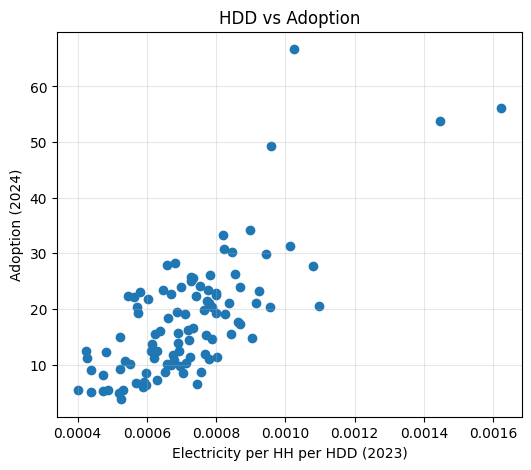

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
plt.scatter(
    final_df["elec_per_hh_per_hdd_2023"],
    final_df["installs_per_1000_full_disp_2024"]
)

plt.xlabel("Electricity per HH per HDD (2023)")
plt.ylabel("Adoption (2024)")
plt.title("HDD vs Adoption")
plt.grid(alpha=0.3)
plt.show()

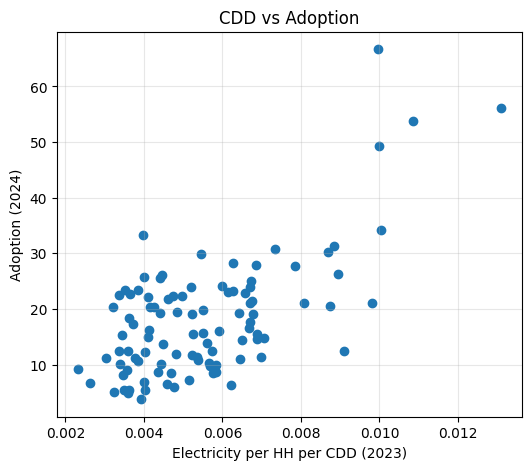

In [52]:
plt.figure(figsize=(6,5))
plt.scatter(
    final_df["elec_per_hh_per_cdd_2023"],
    final_df["installs_per_1000_full_disp_2024"]
)

plt.xlabel("Electricity per HH per CDD (2023)")
plt.ylabel("Adoption (2024)")
plt.title("CDD vs Adoption")
plt.grid(alpha=0.3)
plt.show()

In [53]:
print("HDD correlation:",
      final_df["elec_per_hh_per_hdd_2023"].corr(
          final_df["installs_per_1000_full_disp_2024"]))

print("CDD correlation:",
      final_df["elec_per_hh_per_cdd_2023"].corr(
          final_df["installs_per_1000_full_disp_2024"]))

HDD correlation: 0.733387785722305
CDD correlation: 0.6488536642290572


In [54]:
final_df[[
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023",
    "elec_per_hh_per_cdd_2023",
    "installs_per_1000_full_disp_2024"
]].corr()

,delivered_share_2013,gas_share_2013,elec_per_hh_per_hdd_2023,elec_per_hh_per_cdd_2023,installs_per_1000_full_disp_2024
delivered_share_2013,1.000000,-0.909784,0.498440,0.301577,0.609002
gas_share_2013,-0.909784,1.000000,-0.428579,-0.194893,-0.514167
elec_per_hh_per_hdd_2023,0.498440,-0.428579,1.000000,0.856294,0.733388
elec_per_hh_per_cdd_2023,0.301577,-0.194893,0.856294,1.000000,0.648854
installs_per_1000_full_disp_2024,0.609002,-0.514167,0.733388,0.648854,1.000000


In [55]:
top_towns = final_df.sort_values(
    "installs_per_1000_full_disp_2024",
    ascending=False
).head(10)

top_towns[[
    "municipality",
    "installs_per_1000_full_disp_2024",
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023",
    "elec_per_hh_per_cdd_2023"
]]

,municipality,installs_per_1000_full_disp_2024,delivered_share_2013,gas_share_2013,elec_per_hh_per_hdd_2023,elec_per_hh_per_cdd_2023
0,wellfleet,66.698888,0.805210,0.046181,0.001024,0.009972
1,oak bluffs,56.069959,0.656869,0.074985,0.001622,0.013090
2,tisbury,53.870293,0.777692,0.020914,0.001446,0.010845
3,eastham,49.325880,0.480728,0.398874,0.000960,0.009978
4,dennis,34.237195,0.195338,0.678647,0.000899,0.010035
5,rutland,33.281005,0.703704,0.019435,0.000820,0.003976
6,brewster,31.363345,0.515832,0.339792,0.001014,0.008830
7,sandwich,30.812989,0.453986,0.457464,0.000823,0.007348
8,falmouth,30.288784,0.415759,0.495473,0.000847,0.008686
9,southborough,29.917924,0.606246,0.333435,0.000943,0.005464


In [56]:
q1 = final_df["installs_per_1000_full_disp_2024"].quantile(0.25)
q3 = final_df["installs_per_1000_full_disp_2024"].quantile(0.75)
iqr = q3 - q1

upper_bound = q3 + 1.5 * iqr

outliers = final_df[
    final_df["installs_per_1000_full_disp_2024"] > upper_bound
]

outliers[[
    "municipality",
    "installs_per_1000_full_disp_2024"
]].sort_values(by="installs_per_1000_full_disp_2024", ascending=False)

,municipality,installs_per_1000_full_disp_2024
0,wellfleet,66.698888
1,oak bluffs,56.069959
2,tisbury,53.870293
3,eastham,49.325880


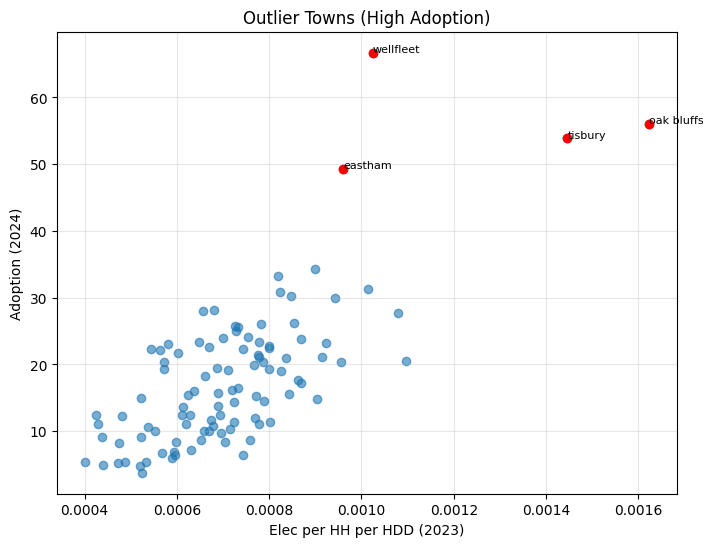

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    final_df["elec_per_hh_per_hdd_2023"],
    final_df["installs_per_1000_full_disp_2024"],
    alpha=0.6
)

# Highlight outliers
plt.scatter(
    outliers["elec_per_hh_per_hdd_2023"],
    outliers["installs_per_1000_full_disp_2024"],
    color="red"
)

# Label them
for _, row in outliers.iterrows():
    plt.text(
        row["elec_per_hh_per_hdd_2023"],
        row["installs_per_1000_full_disp_2024"],
        row["municipality"],
        fontsize=8
    )

plt.xlabel("Elec per HH per HDD (2023)")
plt.ylabel("Adoption (2024)")
plt.title("Outlier Towns (High Adoption)")
plt.grid(alpha=0.3)
plt.show()

In [58]:
coastal_towns = ["truro", "provincetown", "edgartown", "chilmark", "west tisbury"]

outliers["type"] = outliers["municipality"].apply(
    lambda x: "coastal" if x in coastal_towns else "inland"
)

outliers

/tmp/ipykernel_42751/1683164020.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outliers["type"] = outliers["municipality"].apply(


,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,hp_accounts_full_disp_2024,summer_cdd_2013,summer_cdd_2023,summer_cdd_2024,summer_mwh_2013,summer_mwh_2023,summer_mwh_2024,elec_per_hh_per_cdd_2023,elec_per_hh_per_cdd_2024,type
0,wellfleet,1924,236,72,1400,0.122661,0.037422,0.727651,295.738046,2069,...,138.0,442.335602,393.047241,512.838081,8392.0,7541.0,7196.0,0.009972,0.006782,inland
1,oak bluffs,2064,259,167,1424,0.125484,0.080911,0.689922,156.492248,1944,...,109.0,442.335602,393.047241,512.838081,16166.0,10619.0,10730.0,0.013090,0.010763,inland
2,tisbury,1886,293,0,1437,0.155355,0.000000,0.761930,165.959703,1912,...,103.0,442.335602,393.047241,512.838081,12022.0,8039.0,8265.0,0.010845,0.008429,inland
3,eastham,2860,463,1170,1214,0.161888,0.409091,0.424476,219.930070,3041,...,150.0,442.335602,393.047241,512.838081,12955.0,11216.0,11202.0,0.009978,0.007183,inland


---
## Original analysis section: `filtered_dataset_eda(1).ipynb`

**What this section contains:** Construction and testing of household- and HDD-normalized winter electricity, including `elec_per_hh_per_hdd_2023` and related comparisons.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving final_dataset_complete.csv to final_dataset_complete.csv


In [ ]:
import pandas as pd

final_df = pd.read_csv("final_dataset_complete.csv")
final_df.head()

,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,winter_mwh_2024,region,winter_hdd_2013,winter_hdd_2023,winter_hdd_2024,electricity_per_HDD_2013,electricity_per_HDD_2023,electricity_per_HDD_2024,electricity_per_HDD_change_13_23,electricity_per_HDD_change_13_24
0,truro,1053,23,41,865,0.021842,0.038936,0.821462,387.464387,1009,...,4976.0,boston,3048.1638,2587.4028,2732.6106,1.610806,1.731466,1.820969,0.120660,0.210163
1,wellfleet,1924,236,72,1400,0.122661,0.037422,0.727651,295.738046,2069,...,5838.0,boston,3048.1638,2587.4028,2732.6106,1.833891,1.971089,2.136419,0.137198,0.302528
2,provincetown,2034,463,446,996,0.227630,0.219272,0.489676,280.727630,2067,...,6554.0,boston,3048.1638,2587.4028,2732.6106,3.464709,2.281438,2.398439,-1.183270,-1.066270
3,west tisbury,921,32,0,587,0.034745,0.000000,0.637351,231.270358,1106,...,6077.0,boston,3048.1638,2587.4028,2732.6106,1.993003,2.083943,2.223881,0.090940,0.230878
4,edgartown,1666,493,174,856,0.295918,0.104442,0.513806,224.489796,1786,...,14123.0,boston,3048.1638,2587.4028,2732.6106,4.830121,4.818732,5.168318,-0.011389,0.338197


In [ ]:
final_df["elec_per_hh_per_hdd_2023"] = (
    final_df["winter_mwh_2023"] /
    (final_df["total_households_2023"] * final_df["winter_hdd_2023"])
)

# clean infinite values
import numpy as np
final_df["elec_per_hh_per_hdd_2023"].replace([np.inf, -np.inf], np.nan, inplace=True)

/tmp/ipykernel_9926/1515011549.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_df["elec_per_hh_per_hdd_2023"].replace([np.inf, -np.inf], np.nan, inplace=True)


In [ ]:
final_df["elec_per_hh_per_hdd_2023"].describe()

,elec_per_hh_per_hdd_2023
count,301.000000
mean,0.000844
std,0.000304
min,0.000401
25%,0.000681
50%,0.000781
75%,0.000917
max,0.002892


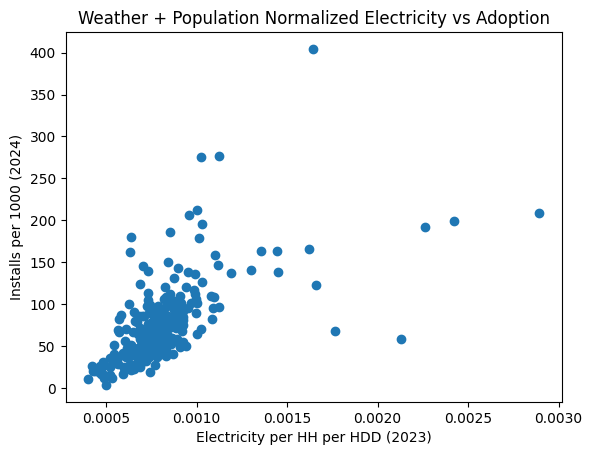

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(
    final_df["elec_per_hh_per_hdd_2023"],
    final_df["installs_per_1000_2024"]
)
plt.xlabel("Electricity per HH per HDD (2023)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("Weather + Population Normalized Electricity vs Adoption")
plt.show()

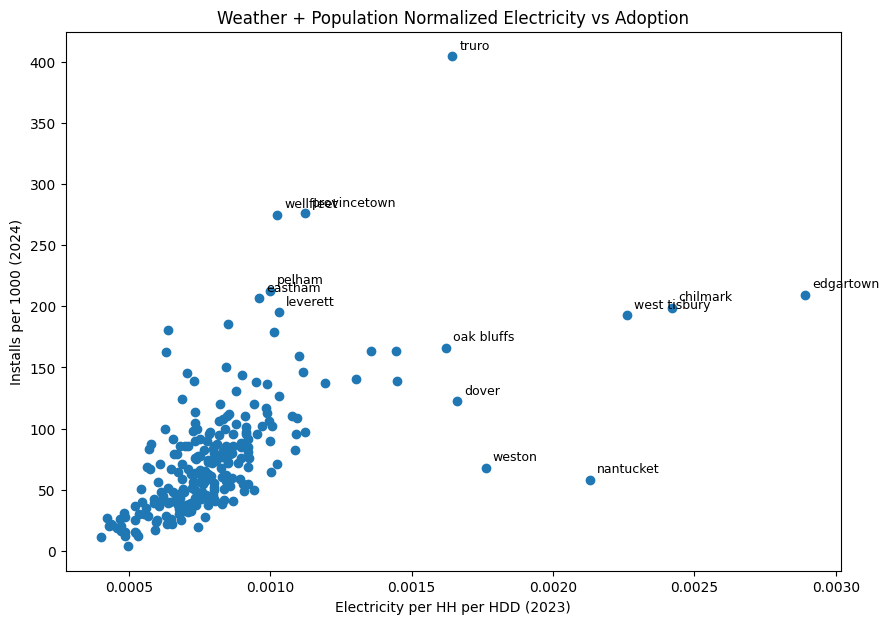

In [ ]:
import matplotlib.pyplot as plt

plot_df = final_df[[
    "municipality",
    "elec_per_hh_per_hdd_2023",
    "installs_per_1000_2024"
]].dropna()

plt.figure(figsize=(10, 7))
plt.scatter(
    plot_df["elec_per_hh_per_hdd_2023"],
    plot_df["installs_per_1000_2024"]
)

plt.xlabel("Electricity per HH per HDD (2023)")
plt.ylabel("Installs per 1000 (2024)")
plt.title("Weather + Population Normalized Electricity vs Adoption")

# top adoption outliers
top_y = plot_df.nlargest(8, "installs_per_1000_2024")

# top x-axis outliers
top_x = plot_df.nlargest(8, "elec_per_hh_per_hdd_2023")

# combine and drop duplicates
outliers = pd.concat([top_y, top_x]).drop_duplicates(subset="municipality")

for _, row in outliers.iterrows():
    plt.annotate(
        row["municipality"],
        (row["elec_per_hh_per_hdd_2023"], row["installs_per_1000_2024"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.show()

In [ ]:
outliers[["municipality", "elec_per_hh_per_hdd_2023", "installs_per_1000_2024"]]

,municipality,elec_per_hh_per_hdd_2023,installs_per_1000_2024
0,truro,0.001644,404.360753
2,provincetown,0.001122,276.245767
1,wellfleet,0.001024,275.012083
7,pelham,0.001000,212.686567
4,edgartown,0.002892,209.406495
5,eastham,0.000960,206.839855
6,chilmark,0.002420,198.952880
8,leverett,0.001032,195.224719
3,west tisbury,0.002263,192.585895
134,nantucket,0.002132,58.263519


In [ ]:
final_df["elec_per_hh_per_hdd_2023"].corr(
    final_df["installs_per_1000_2024"]
)

np.float64(0.6116556402540776)

In [ ]:
filtered_df = final_df[final_df["installs_per_1000_2024"] < 300]

filtered_df["elec_per_hh_per_hdd_2023"].corr(
    filtered_df["installs_per_1000_2024"]
)

np.float64(0.6003770199472167)

In [ ]:
print("WSR:", final_df["wsr_2023"].corr(final_df["installs_per_1000_2024"]))

print("Elec/HDD:", final_df["electricity_per_HDD_2023"].corr(
    final_df["installs_per_1000_2024"]
))

print("Elec/HH/HDD:", final_df["elec_per_hh_per_hdd_2023"].corr(
    final_df["installs_per_1000_2024"]
))

WSR: 0.09320672448697899
Elec/HDD: -0.2906650722046876
Elec/HH/HDD: 0.6116556402540776


In [ ]:
final_df["elec_per_hh_per_hdd_2023"] = (
    final_df["winter_mwh_2023"] /
    (final_df["total_households_2023"] * final_df["winter_hdd_2023"])
)

In [ ]:
import numpy as np
final_df["elec_per_hh_per_hdd_2023"].replace([np.inf, -np.inf], np.nan, inplace=True)

/tmp/ipykernel_9926/3559919671.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_df["elec_per_hh_per_hdd_2023"].replace([np.inf, -np.inf], np.nan, inplace=True)


In [ ]:
final_df.to_csv("final_dataset_updated.csv", index=False)

In [ ]:
from google.colab import files
files.download("final_dataset_updated.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving heatpump_filters.xlsx to heatpump_filters.xlsx


In [ ]:
import pandas as pd

hp_filtered = pd.read_excel("heatpump_filters.xlsx")
hp_filtered.head()

,Municipality,Installed heat pumps (accounts),Installed heat pumps (locations)
0,Abington,*,*
1,Acton,187,186
2,Acushnet,*,*
3,Adams,*,*
4,Agawam,*,*


In [ ]:
hp_filtered.columns.tolist()

['Municipality',
 'Installed heat pumps (accounts)',
 'Installed heat pumps (locations)']

In [ ]:
import pandas as pd
import numpy as np

hp_filtered = pd.read_excel("heatpump_filters.xlsx")

# clean column names
hp_filtered.columns = hp_filtered.columns.str.strip().str.lower()

# rename for convenience
hp_filtered.rename(columns={
    "installed heat pumps (accounts)": "hp_accounts_full_disp"
}, inplace=True)

In [ ]:
hp_filtered["municipality"] = (
    hp_filtered["municipality"]
    .astype(str)
    .str.strip()
    .str.lower()
)

In [ ]:
hp_filtered["hp_accounts_full_disp"] = (
    hp_filtered["hp_accounts_full_disp"]
    .replace("*", np.nan)
)

hp_filtered["hp_accounts_full_disp"] = pd.to_numeric(
    hp_filtered["hp_accounts_full_disp"], errors="coerce"
)

/tmp/ipykernel_9926/3096571673.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace("*", np.nan)


In [ ]:
hp_filtered = hp_filtered.merge(
    final_df[["municipality", "total_households_2024"]],
    on="municipality",
    how="left"
)

In [ ]:
hp_filtered["installs_per_1000_full_disp_2024"] = (
    hp_filtered["hp_accounts_full_disp"] /
    hp_filtered["total_households_2024"] * 1000
)

In [ ]:
final_df = final_df.merge(
    hp_filtered[["municipality", "installs_per_1000_full_disp_2024"]],
    on="municipality",
    how="left"
)

In [ ]:
final_df["elec_per_hh_per_hdd_2023"].corr(
    final_df["installs_per_1000_full_disp_2024"]
)

np.float64(0.7333876898999641)

In [ ]:
final_df["installs_per_1000_full_disp_2024"].count()

np.int64(103)

In [ ]:
filtered_df = final_df[
    (final_df["installs_per_1000_full_disp_2024"] < 300)
]

filtered_df["elec_per_hh_per_hdd_2023"].corr(
    filtered_df["installs_per_1000_full_disp_2024"]
)

np.float64(0.7333876898999641)

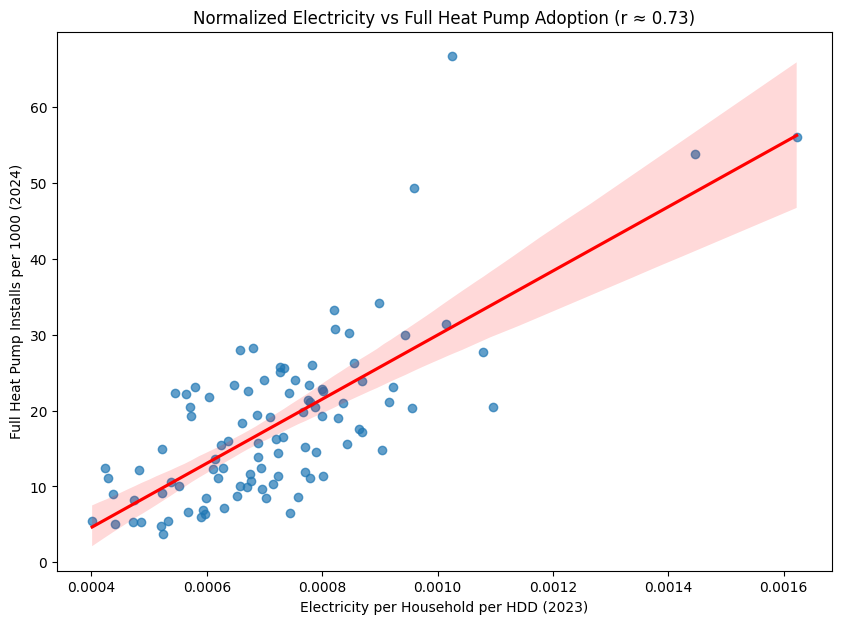

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = final_df[[
    "municipality",
    "elec_per_hh_per_hdd_2023",
    "installs_per_1000_full_disp_2024"
]].dropna()

plt.figure(figsize=(10, 7))

sns.regplot(
    data=plot_df,
    x="elec_per_hh_per_hdd_2023",
    y="installs_per_1000_full_disp_2024",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.xlabel("Electricity per Household per HDD (2023)")
plt.ylabel("Full Heat Pump Installs per 1000 (2024)")
plt.title("Normalized Electricity vs Full Heat Pump Adoption (r ≈ 0.73)")

plt.show()

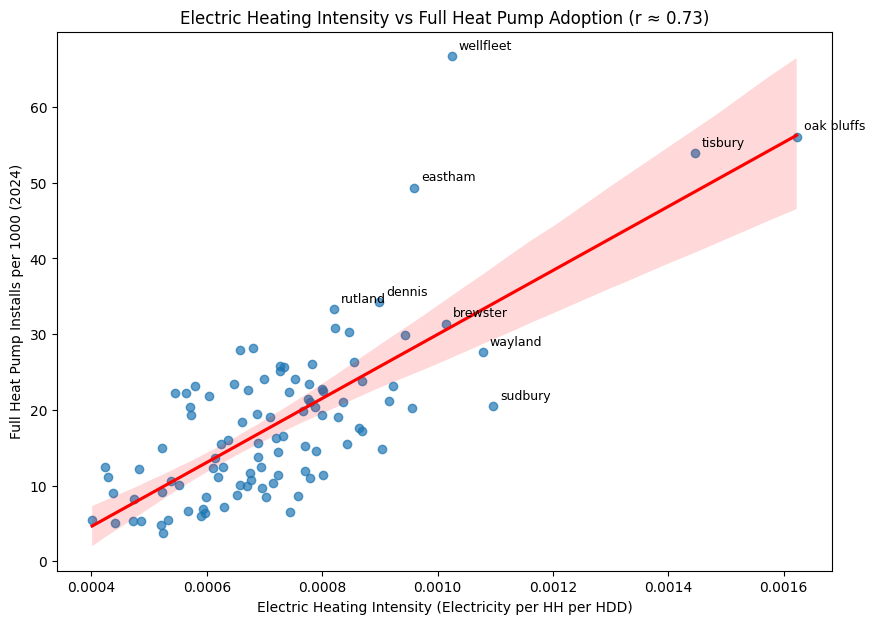

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plot_df = final_df[[
    "municipality",
    "elec_per_hh_per_hdd_2023",
    "installs_per_1000_full_disp_2024"
]].dropna()

plt.figure(figsize=(10, 7))

sns.regplot(
    data=plot_df,
    x="elec_per_hh_per_hdd_2023",
    y="installs_per_1000_full_disp_2024",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

# 🔥 pick outliers
top_y = plot_df.nlargest(6, "installs_per_1000_full_disp_2024")
top_x = plot_df.nlargest(6, "elec_per_hh_per_hdd_2023")

outliers = pd.concat([top_y, top_x]).drop_duplicates()

# label them
for _, row in outliers.iterrows():
    plt.annotate(
        row["municipality"],
        (row["elec_per_hh_per_hdd_2023"], row["installs_per_1000_full_disp_2024"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Electric Heating Intensity (Electricity per HH per HDD)")
plt.ylabel("Full Heat Pump Installs per 1000 (2024)")
plt.title("Electric Heating Intensity vs Full Heat Pump Adoption (r ≈ 0.73)")

plt.show()

In [ ]:
outliers[[
    "municipality",
    "elec_per_hh_per_hdd_2023",
    "installs_per_1000_full_disp_2024"
]]

,municipality,elec_per_hh_per_hdd_2023,installs_per_1000_full_disp_2024
1,wellfleet,0.001024,66.698888
5,eastham,0.000960,49.325880
12,tisbury,0.001446,53.870293
15,oak bluffs,0.001622,56.069959
20,dennis,0.000899,34.237195
36,wayland,0.001078,27.657053
40,sudbury,0.001096,20.485946


In [ ]:
final_df[[
    "elec_per_hh_per_hdd_2023",
    "delivered_share_2013",
    "gas_share_2013",
    "installs_per_1000_full_disp_2024"
]].corr()

,elec_per_hh_per_hdd_2023,delivered_share_2013,gas_share_2013,installs_per_1000_full_disp_2024
elec_per_hh_per_hdd_2023,1.000000,0.498440,-0.428579,0.733388
delivered_share_2013,0.498440,1.000000,-0.909784,0.609002
gas_share_2013,-0.428579,-0.909784,1.000000,-0.514167
installs_per_1000_full_disp_2024,0.733388,0.609002,-0.514167,1.000000


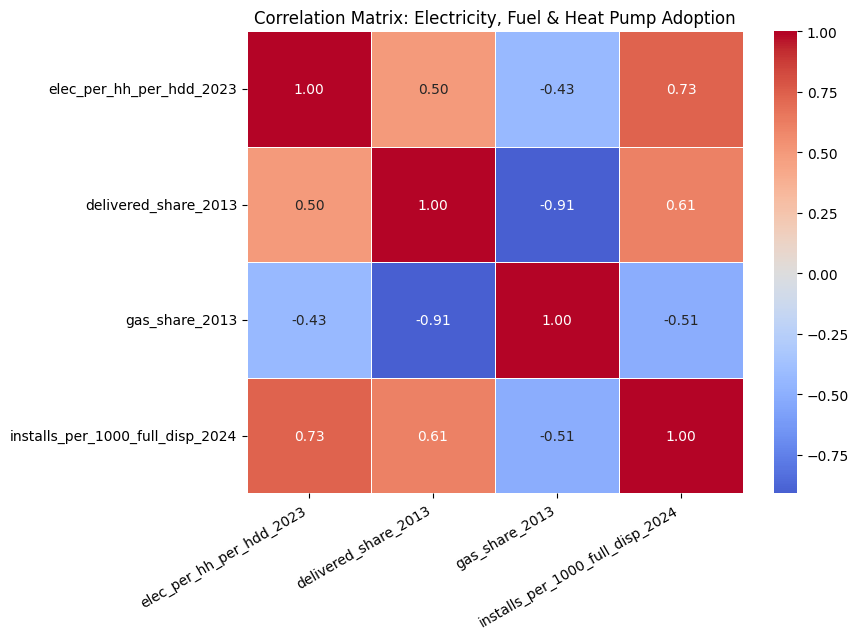

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# select relevant columns
corr_df = final_df[[
    "elec_per_hh_per_hdd_2023",
    "delivered_share_2013",
    "gas_share_2013",
    "installs_per_1000_full_disp_2024"
]]

# compute correlation
corr_matrix = corr_df.corr()

# plot
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,        # show numbers
    fmt=".2f",         # 2 decimal places
    cmap="coolwarm",   # color scheme
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix: Electricity, Fuel & Heat Pump Adoption")
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)

plt.show()

In [ ]:
hp_filtered = hp_filtered[[
    "municipality",
    "hp_accounts_full_disp",
    "installs_per_1000_full_disp_2024"
]]

In [ ]:
final_df = final_df.merge(
    hp_filtered,
    on="municipality",
    how="left"
)

In [ ]:
final_df = final_df.merge(
    hp_filtered[["municipality", "hp_accounts_full_disp"]],
    on="municipality",
    how="left"
)

In [ ]:
final_df.rename(columns={
    "hp_accounts_full_disp": "hp_accounts_full_disp_2024"
}, inplace=True)

In [ ]:
final_df.to_csv("final_dataset_completev1.csv", index=False)

In [ ]:
from google.colab import files
files.download("final_dataset_completev1.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
(final_df["installs_per_1000_full_disp_2024_x"] ==
 final_df["installs_per_1000_full_disp_2024_y"]).all()

np.False_

In [ ]:
diff = final_df[
    final_df["installs_per_1000_full_disp_2024_x"] !=
    final_df["installs_per_1000_full_disp_2024_y"]
]

diff[[
    "municipality",
    "installs_per_1000_full_disp_2024_x",
    "installs_per_1000_full_disp_2024_y"
]].head(20)

,municipality,installs_per_1000_full_disp_2024_x,installs_per_1000_full_disp_2024_y
0,truro,NaN,NaN
2,provincetown,NaN,NaN
3,west tisbury,NaN,NaN
4,edgartown,NaN,NaN
6,chilmark,NaN,NaN
7,pelham,NaN,NaN
8,leverett,NaN,NaN
9,shutesbury,NaN,NaN
10,gill,NaN,NaN
13,harvard,NaN,NaN


In [ ]:
final_df = final_df.drop(columns=[
    "installs_per_1000_full_disp_2024_y",
    "hp_accounts_full_disp_y"
])

In [ ]:
final_df = final_df.rename(columns={
    "installs_per_1000_full_disp_2024_x": "installs_per_1000_full_disp_2024",
    "hp_accounts_full_disp_x": "hp_accounts_full_disp_2024"
})

In [ ]:
final_df.to_csv("final_dataset_clean.csv", index=False)

In [ ]:
from google.colab import files
files.download("final_dataset_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

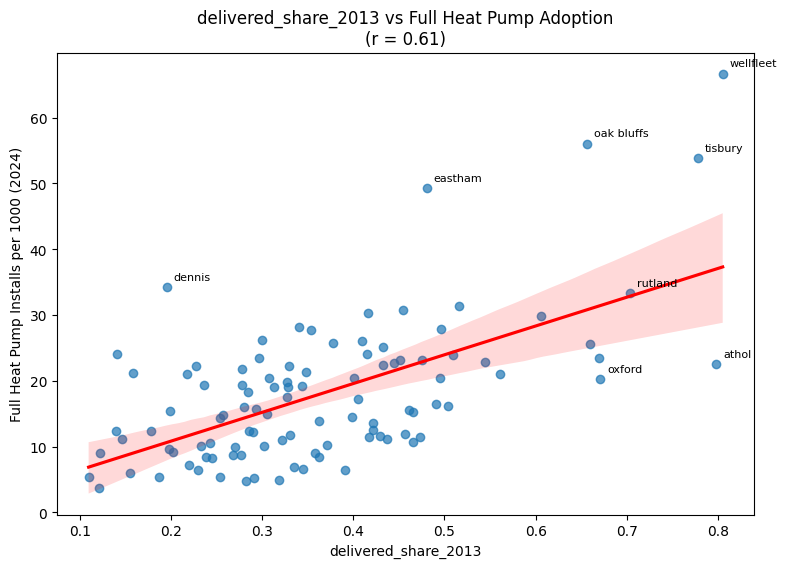

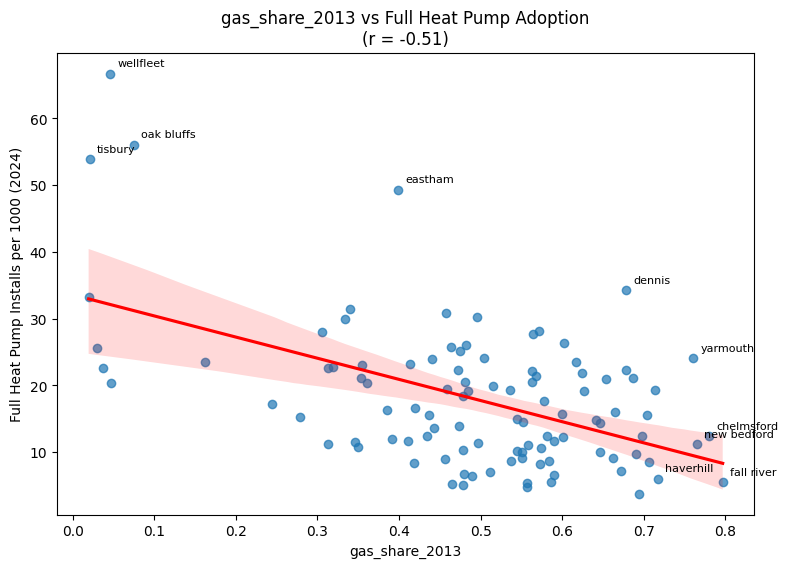

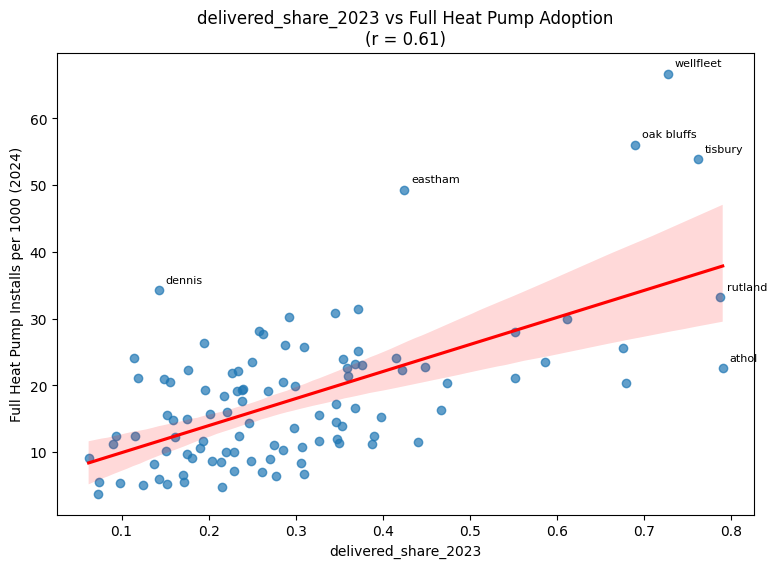

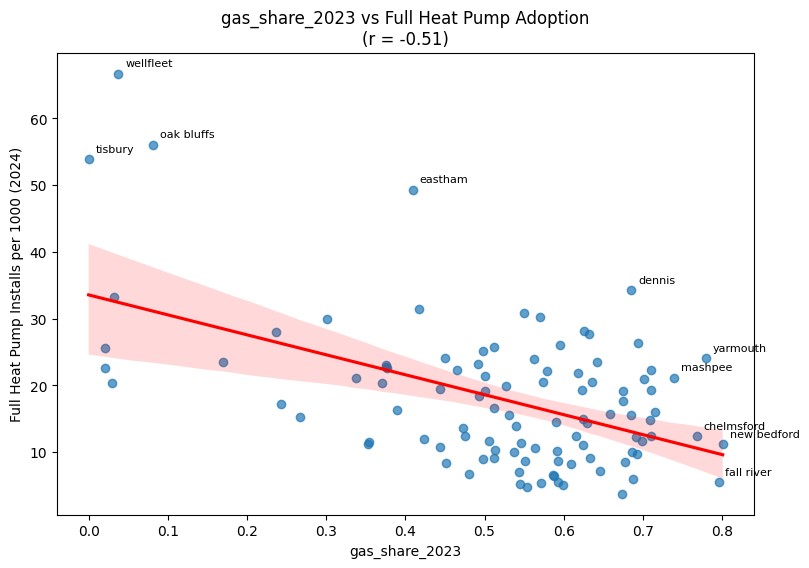

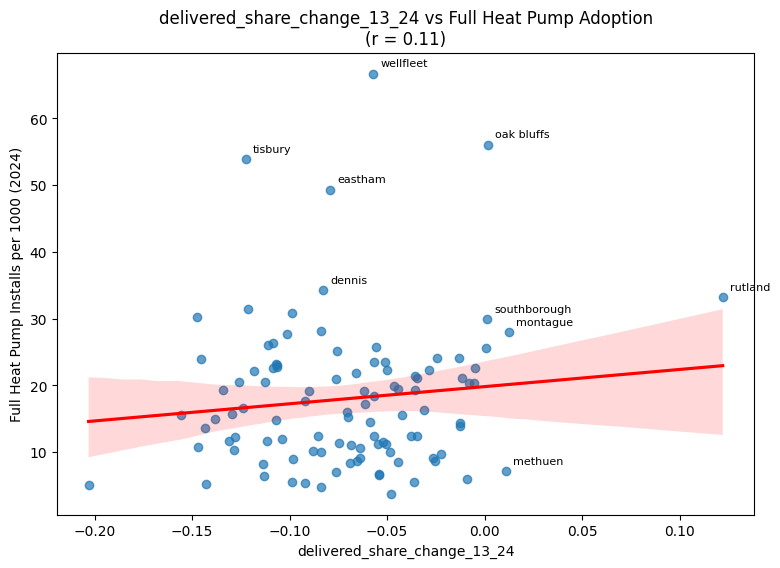

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

y_col = "installs_per_1000_full_disp_2024"

predictors = [
    "delivered_share_2013",
    "gas_share_2013",
    "delivered_share_2023",
    "gas_share_2023",
    "delivered_share_change_13_24"
]

for x_col in predictors:
    plot_df = final_df[[x_col, y_col, "municipality"]].dropna()
    corr = plot_df[x_col].corr(plot_df[y_col])

    plt.figure(figsize=(9, 6))
    sns.regplot(
        data=plot_df,
        x=x_col,
        y=y_col,
        scatter_kws={"alpha": 0.7},
        line_kws={"color": "red"}
    )

    # label top 5 adoption outliers + top 5 x outliers
    top_y = plot_df.nlargest(5, y_col)
    top_x = plot_df.nlargest(5, x_col)
    outliers = pd.concat([top_y, top_x]).drop_duplicates(subset="municipality")

    for _, row in outliers.iterrows():
        plt.annotate(
            row["municipality"],
            (row[x_col], row[y_col]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    plt.title(f"{x_col} vs Full Heat Pump Adoption\n(r = {corr:.2f})")
    plt.xlabel(x_col)
    plt.ylabel("Full Heat Pump Installs per 1000 (2024)")
    plt.show()

In [ ]:
for col in [
    "delivered_share_2013",
    "gas_share_2013",
    "delivered_share_2023",
    "gas_share_2023",
    "delivered_share_change_13_24"
]:
    print(col, final_df[col].corr(final_df["installs_per_1000_full_disp_2024"]))

delivered_share_2013 0.6090015124878467
gas_share_2013 -0.5141674676419921
delivered_share_2023 0.6122751631467979
gas_share_2023 -0.5067202784095792
delivered_share_change_13_24 0.11403025939858018


In [ ]:
filtered_towns = final_df[
    final_df["installs_per_1000_full_disp_2024"].notna()
]["municipality"]

print(len(filtered_towns))  # should be 103

filtered_towns.head(20)

103


,municipality
1,wellfleet
5,eastham
11,brewster
12,tisbury
15,oak bluffs
20,dennis
30,sandwich
32,southborough
33,harwich
36,wayland


In [ ]:
filtered_towns_df = final_df[
    final_df["installs_per_1000_full_disp_2024"].notna()
][["municipality"]].sort_values("municipality")

filtered_towns_df.reset_index(drop=True, inplace=True)

filtered_towns_df.head(20)

,municipality
0,acton
1,amherst
2,andover
3,arlington
4,ashland
5,athol
6,attleboro
7,auburn
8,barnstable
9,belchertown


In [ ]:
filtered_towns_df.to_csv("filtered_full_disp_towns.csv", index=False)

from google.colab import files
files.download("filtered_full_disp_towns.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
filtered_towns_df = final_df[
    final_df["installs_per_1000_full_disp_2024"].notna()
][[
    "municipality",
    "installs_per_1000_full_disp_2024"
]].sort_values("installs_per_1000_full_disp_2024", ascending=False)

filtered_towns_df.head(10)

,municipality,installs_per_1000_full_disp_2024
1,wellfleet,66.698888
15,oak bluffs,56.069959
12,tisbury,53.870293
5,eastham,49.325880
20,dennis,34.237195
57,rutland,33.281005
11,brewster,31.363345
30,sandwich,30.812989
37,falmouth,30.288784
32,southborough,29.917924


In [ ]:
len(final_df)  # total towns
len(filtered_towns_df)  # filtered towns (103)

103